# Import Libraries

The first step in this project is to import all necessary Python libraries. All libraries required, ranging from data manipulation and visualization to model training and production artifact serialization, are collected and imported at the beginning.

This step is essential to prepare the working environment with all required functions and tools. Consolidating all imports at the top of the notebook is a best practice that ensures well-structured, clean, and easily maintainable code. It guarantees that all tools are ready before data processing begins.

By running the code cell below, the environment will be equipped with specialized libraries:
- Dataset Management & System: `os` for filesystem operations, `json` for metadata serialization, and `gdown` to automatically download the dataset from Google Drive into the `datasets` folder.
- Data Manipulation and Numerical Computing: `pandas` for DataFrame manipulation, `numpy` for numerical operations, and `math` for mathematical helper functions.
- Data Visualization: `matplotlib` and `seaborn` for creating exploratory plots and statistical graphics.
- Data Preparation and Preprocessing: `train_test_split` for dataset splitting, and `StandardScaler` for feature scaling.
- Modeling: Multiple classification algorithms including `KNeighborsClassifier`, `LogisticRegression`, `XGBClassifier`, and `LGBMClassifier`.
- Model Evaluation and Optimization: `accuracy_score`, `classification_report`, and `confusion_matrix` to measure performance, along with `GridSearchCV` and `StratifiedKFold` for hyperparameter tuning.
- Production Artifact Export: `joblib` to serialize the trained LightGBM model and fitted scaler for seamless integration with the FastAPI backend and Streamlit dashboard.

In [1]:
import os
import json
import math
import joblib
import gdown
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import lightgbm as lgb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Data Loading

In this stage, the dataset is automatically downloaded from Google Drive using `gdown` into the `datasets/` directory if it is not already present. Next, the data is loaded using `read_csv()` from the `pandas` library and stored into a DataFrame named `df`. Finally, the first five rows are displayed using `.head()`.

This approach ensures that the notebook is self-contained and can be executed directly in Google Colab without needing to manually upload the dataset file beforehand.

By running the code cell below, `diabetes_dataset.csv` will be stored in the `datasets/` folder and loaded into memory. Displaying the first five rows confirms successful loading and provides an initial overview of columns such as `age`, `gender`, `ethnicity`, through `diagnosed_diabetes`.

In [2]:
os.makedirs('datasets', exist_ok=True)
dataset_path = 'datasets/diabetes_dataset.csv'

if not os.path.exists(dataset_path):
    file_id = '1aQecxs7KYVtRPwyyXMA7ofo7laAbt5i6'
    gdown_url = f'https://drive.google.com/uc?id={file_id}'
    gdown.download(gdown_url, dataset_path, quiet=False)
else:
    print(f"Dataset is already exist in: {dataset_path}")

df = pd.read_csv(dataset_path)
df.head()

Downloading...
From: https://drive.google.com/uc?id=1aQecxs7KYVtRPwyyXMA7ofo7laAbt5i6
To: /content/datasets/diabetes_dataset.csv
100%|██████████| 14.4M/14.4M [00:00<00:00, 33.3MB/s]


,age,gender,ethnicity,education_level,income_level,employment_status,smoking_status,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,...,hdl_cholesterol,ldl_cholesterol,triglycerides,glucose_fasting,glucose_postprandial,insulin_level,hba1c,diabetes_risk_score,diabetes_stage,diagnosed_diabetes
0,58,Male,Asian,Highschool,Lower-Middle,Employed,Never,0,215,5.7,...,41,160,145,136,236,6.36,8.18,29.6,Type 2,1
1,48,Female,White,Highschool,Middle,Employed,Former,1,143,6.7,...,55,50,30,93,150,2.00,5.63,23.0,No Diabetes,0
2,60,Male,Hispanic,Highschool,Middle,Unemployed,Never,1,57,6.4,...,66,99,36,118,195,5.07,7.51,44.7,Type 2,1
3,74,Female,Black,Highschool,Low,Retired,Never,0,49,3.4,...,50,79,140,139,253,5.28,9.03,38.2,Type 2,1
4,46,Male,White,Graduate,Middle,Retired,Never,1,109,7.2,...,52,125,160,137,184,12.74,7.20,23.5,Type 2,1


# Data Understanding (Exploratory Data Analysis - EDA)

In this phase, we perform an initial investigation of the dataset known as Exploratory Data Analysis (EDA). This is a fundamental step to deeply understand the data's characteristics before moving on to data preparation and modeling.

The main objective of EDA is to understand data distributions, discover patterns, identify anomalies such as outliers, and validate underlying assumptions. Without a solid understanding of the data, one risks choosing inappropriate preprocessing techniques or building sub-optimal models. EDA enables informed, data-driven decisions at every subsequent stage.

This EDA process is structured into several subsections:
1. Variable Description: Understanding the meaning and data type of each column.
2. Data Quality Checks: Verifying the absence of missing values and duplicate records.
3. Outlier and Distribution Analysis: Identifying extreme values and visualizing numeric feature distributions.
4. Correlation Analysis: Examining linear relationships and potential multicollinearity among numerical features.

Findings from each section will serve as the foundation for design choices in Data Preparation.

## Variable Description

In this subsection, foundational checks are performed to understand the structure and content of the dataset using three primary functions:
1. `.info()`: Provides a technical summary of the DataFrame, including the number of entries, column names, non-null counts, and data types (`Dtype`).
2. `.describe()`: Computes descriptive statistics (mean, standard deviation, min, max, quartiles) for all numerical columns.
3. `.shape`: Retrieves the exact dimensions of the dataset formatted as (rows, columns).

These steps are crucial for initial validation. `.info()` identifies column data types, determining required preprocessing (e.g., categorical `object` columns need encoding). `.describe()` provides a first look at numerical distributions and scales, flagging potential anomalies. `.shape` confirms the overall scale of the data.

Key insights gained from executing the code below:
1. Data Dimensions: Confirmed 100,000 rows and 31 columns.
2. Data Types: Three main types: `int64` and `float64` for numerical features, and `object` for textual categorical features.
3. Zero Missing Values: All columns contain 100,000 non-null entries, indicating complete data.
4. Baseline Statistics: The average patient age is approximately 50 years, ranging from 18 to 90 years.

In [3]:
df.shape

(100000, 31)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 31 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   age                                 100000 non-null  int64  
 1   gender                              100000 non-null  object 
 2   ethnicity                           100000 non-null  object 
 3   education_level                     100000 non-null  object 
 4   income_level                        100000 non-null  object 
 5   employment_status                   100000 non-null  object 
 6   smoking_status                      100000 non-null  object 
 7   alcohol_consumption_per_week        100000 non-null  int64  
 8   physical_activity_minutes_per_week  100000 non-null  int64  
 9   diet_score                          100000 non-null  float64
 10  sleep_hours_per_day                 100000 non-null  float64
 11  screen_time_hours_per_day  

In [5]:
df.describe()

,age,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,sleep_hours_per_day,screen_time_hours_per_day,family_history_diabetes,hypertension_history,cardiovascular_history,bmi,...,cholesterol_total,hdl_cholesterol,ldl_cholesterol,triglycerides,glucose_fasting,glucose_postprandial,insulin_level,hba1c,diabetes_risk_score,diagnosed_diabetes
count,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50.12041,2.003670,118.911640,5.994787,6.997818,5.996468,0.219410,0.250800,0.079200,25.612653,...,185.978110,54.042790,103.000430,121.462650,111.11712,160.035050,9.061242,6.520776,30.222362,0.599980
std,15.60460,1.417779,84.409662,1.780954,1.094622,2.468406,0.413849,0.433476,0.270052,3.586705,...,32.013005,10.267374,33.390256,43.372619,13.59561,30.935472,4.954060,0.813921,9.061505,0.489904
min,18.00000,0.000000,0.000000,0.000000,3.000000,0.500000,0.000000,0.000000,0.000000,15.000000,...,100.000000,20.000000,50.000000,30.000000,60.00000,70.000000,2.000000,4.000000,2.700000,0.000000
25%,39.00000,1.000000,57.000000,4.800000,6.300000,4.300000,0.000000,0.000000,0.000000,23.200000,...,164.000000,47.000000,78.000000,91.000000,102.00000,139.000000,5.090000,5.970000,23.800000,0.000000
50%,50.00000,2.000000,100.000000,6.000000,7.000000,6.000000,0.000000,0.000000,0.000000,25.600000,...,186.000000,54.000000,102.000000,121.000000,111.00000,160.000000,8.790000,6.520000,29.000000,1.000000
75%,61.00000,3.000000,160.000000,7.200000,7.700000,7.700000,0.000000,1.000000,0.000000,28.000000,...,208.000000,61.000000,126.000000,151.000000,120.00000,181.000000,12.450000,7.070000,35.600000,1.000000
max,90.00000,10.000000,833.000000,10.000000,10.000000,16.800000,1.000000,1.000000,1.000000,39.200000,...,318.000000,98.000000,263.000000,344.000000,172.00000,287.000000,32.220000,9.800000,67.200000,1.000000


## Missing Values & Duplicate Check

In this subsection, essential data quality checks are conducted: verifying missing values and duplicate records.

Missing values and duplicates can distort analytical insights and model performance. Missing data requires imputation or removal, while duplicates can introduce unintended sample weights and model bias. Therefore, verifying data integrity is an indispensable quality assurance step.

The results confirm excellent dataset quality: zero missing values and zero duplicates were found, allowing us to proceed without imputation or deduplication.

### Total Missing Values Check

The code below performs a quick verification across the entire dataset. `.isnull()` flags empty cells as `True`, and `.sum().sum()` aggregates them. A result of `0` confirms that there are no missing values in the DataFrame.

In [6]:
total_missing = df.isnull().sum().sum()
print(f"Total missing values across dataset: {total_missing}")

Total missing values across dataset: 0


### Duplicate Rows Check

The code below checks for duplicate rows. `.duplicated()` marks identical rows, and `.sum()` computes the total count. A result of `0` confirms every record is unique.

In [7]:
df.duplicated().sum()

np.int64(0)

## Outlier Analysis

In this subsection, outliers in numerical features are analyzed using two complementary approaches: visualization via Box Plots and quantitative assessment via the Interquartile Range (IQR) method.

Outliers are data points that significantly deviate from the majority of observations. Their presence can affect statistical calculations and sensitive models (such as KNN and Logistic Regression). Identifying outliers early helps in understanding distributions and selecting appropriate modeling strategies.

The analysis reveals that several numerical features contain outliers. This finding informs the choice of tree-based ensemble models (such as LightGBM and XGBoost), which are naturally robust to outliers.

### Outlier Visualization with Box Plots

The code below generates box plots for all numerical features. It defines the numerical column list, configures a multi-panel subplot layout, and iterates through each feature. This visualizes medians, quartiles, and data points extending beyond the whiskers (outliers).

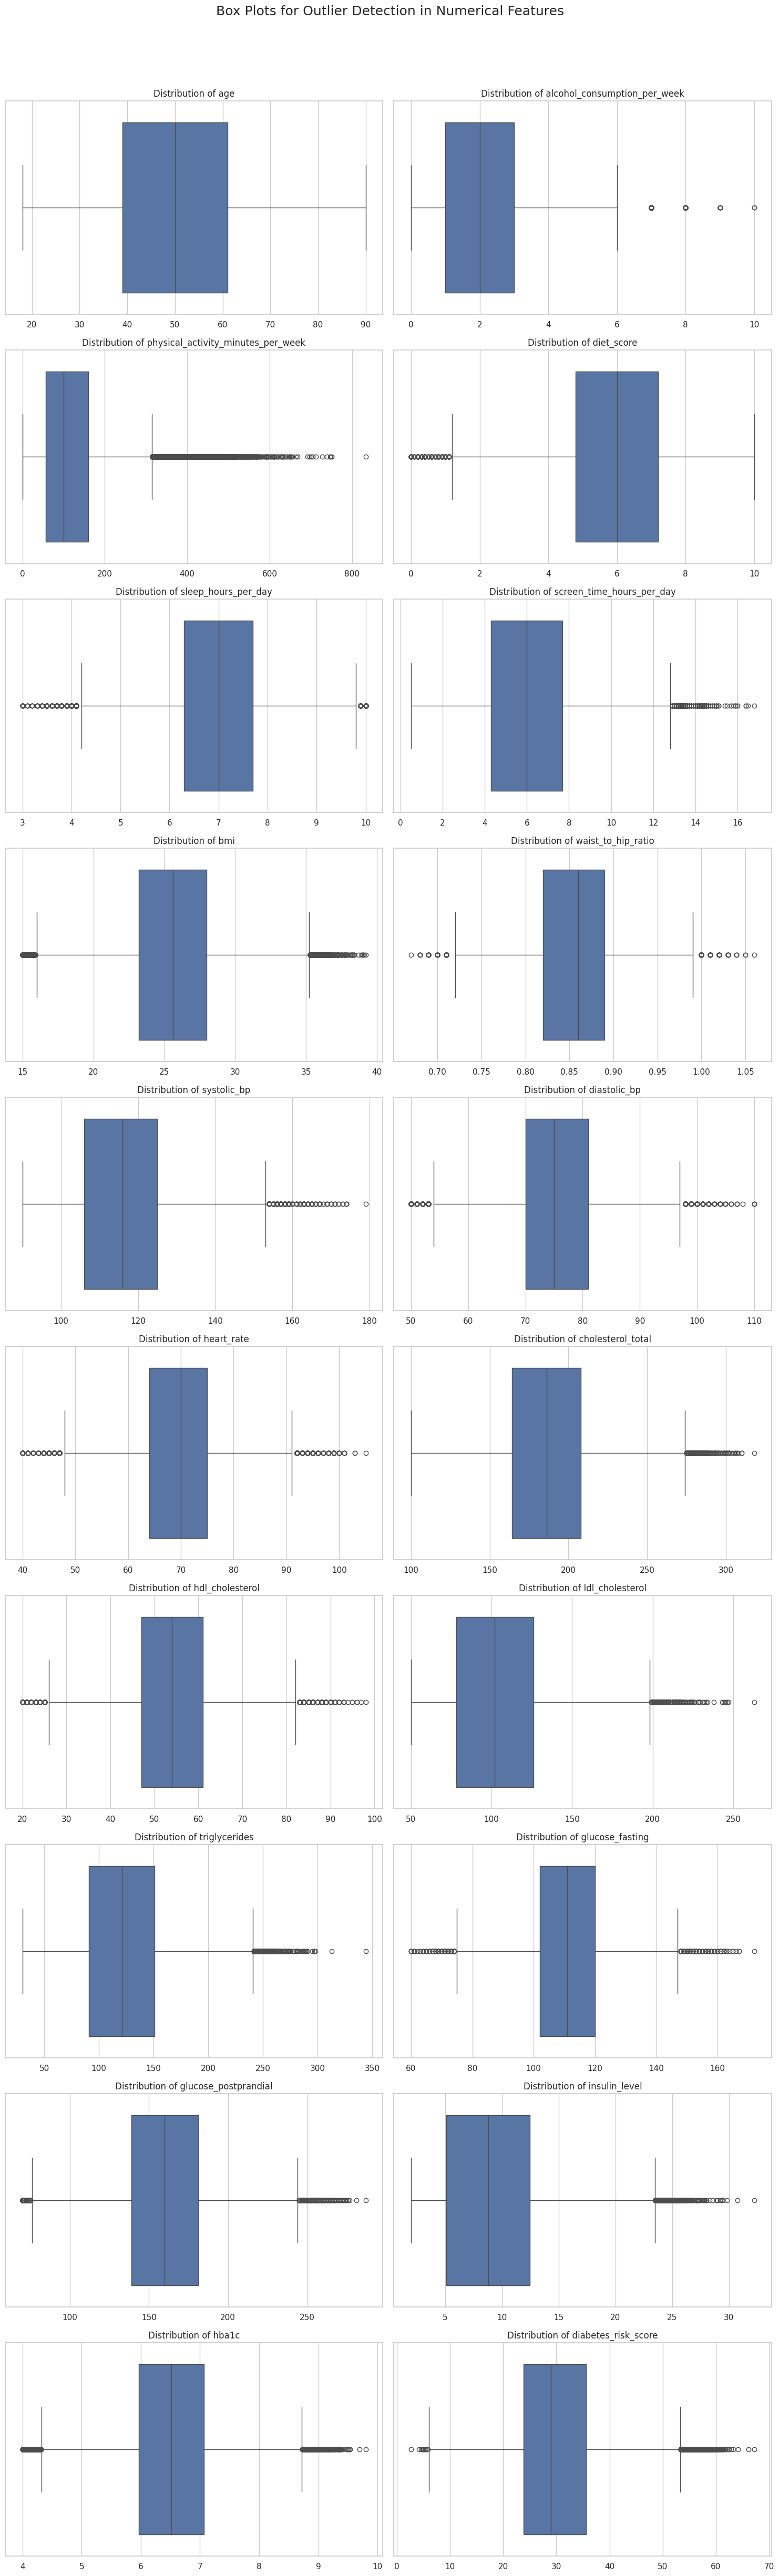

In [8]:
numerical_cols = [
  'age',
  'alcohol_consumption_per_week',
  'physical_activity_minutes_per_week',
  'diet_score',
  'sleep_hours_per_day',
  'screen_time_hours_per_day',
  'bmi',
  'waist_to_hip_ratio',
  'systolic_bp',
  'diastolic_bp',
  'heart_rate',
  'cholesterol_total',
  'hdl_cholesterol',
  'ldl_cholesterol',
  'triglycerides',
  'glucose_fasting',
  'glucose_postprandial',
  'insulin_level',
  'hba1c',
  'diabetes_risk_score'
]

num_of_cols = len(numerical_cols)
plot_cols = 2
plot_rows = math.ceil(num_of_cols / plot_cols)

sns.set(style="whitegrid")
plt.figure(figsize=(15, 5 * plot_rows))
plt.suptitle('Box Plots for Outlier Detection in Numerical Features', fontsize=18, y=0.98)

for i, col in enumerate(numerical_cols, 1):
  plt.subplot(plot_rows, plot_cols, i)
  sns.boxplot(x=df[col])
  plt.title(f'Distribution of {col}', fontsize=12)
  plt.xlabel('')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Outlier Quantification using the IQR Method

Following visual inspection, the code below quantitatively calculates outliers using the IQR method. For each numerical feature, Quartile 1 (Q1), Quartile 3 (Q3), and IQR (Q3 - Q1) are computed, with outlier thresholds set at Q1 - 1.5 * IQR and Q3 + 1.5 * IQR. A summary report outputs the count and percentage of outliers per feature, showing that `physical_activity_minutes_per_week` exhibits the highest outlier proportion (3.20%).

In [9]:
print("Outlier Counts and Percentages (IQR Method):")
for col in numerical_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
  num_outliers = len(outliers)

  total_data = len(df)
  percentage = (num_outliers / total_data) * 100

  if num_outliers > 0:
    print(f"- {col}: {num_outliers} outliers ({percentage:.2f}%)")

Outlier Counts and Percentages (IQR Method):
- alcohol_consumption_per_week: 458 outliers (0.46%)
- physical_activity_minutes_per_week: 3199 outliers (3.20%)
- diet_score: 337 outliers (0.34%)
- sleep_hours_per_day: 900 outliers (0.90%)
- screen_time_hours_per_day: 305 outliers (0.30%)
- bmi: 744 outliers (0.74%)
- waist_to_hip_ratio: 273 outliers (0.27%)
- systolic_bp: 530 outliers (0.53%)
- diastolic_bp: 731 outliers (0.73%)
- heart_rate: 855 outliers (0.85%)
- cholesterol_total: 309 outliers (0.31%)
- hdl_cholesterol: 565 outliers (0.56%)
- ldl_cholesterol: 349 outliers (0.35%)
- triglycerides: 301 outliers (0.30%)
- glucose_fasting: 745 outliers (0.74%)
- glucose_postprandial: 634 outliers (0.63%)
- insulin_level: 326 outliers (0.33%)
- hba1c: 618 outliers (0.62%)
- diabetes_risk_score: 914 outliers (0.91%)


## Data Distributions

In this subsection, histograms will be generated and displayed for each numerical feature in the dataset. These histograms will also be overlaid with a Kernel Density Estimate (KDE) curve, providing a smoother visualization of the data distribution's shape.

Visualizing data distribution is crucial for understanding how values ​​within each feature are spread out. It helps answer questions such as: Is the data normally distributed (symmetrical)? Is the data right-skewed or left-skewed? Significant skewness in certain features can impact the performance of specific models and may warrant consideration for data transformation (although this project relies on robust models).

Executing the code below will produce a series of histograms showing the distribution shape of each numerical variable. From these plots, one can observe that while some features—such as `age`—exhibit a relatively uniform distribution, many clinical features (e.g., `insulin_level`, `triglycerides`, and `physical_activity_minutes_per_week`) display a strongly right-skewed distribution. This indicates that the majority of patients have relatively low values ​​for these features, yet there is a small subset of patients with very high values—a pattern consistent with the previously identified outliers.

### Distribution Visualization with Histograms

The code below automatically selects all numeric columns from the DataFrame. It then iterates through each of these columns, creating a histogram (`sns.histplot`) to display the frequency of each value range. Including the `kde=True` parameter draws a probability density estimation line, which helps clarify the shape of the data distribution. The result is a series of informative visualizations for each numeric feature.

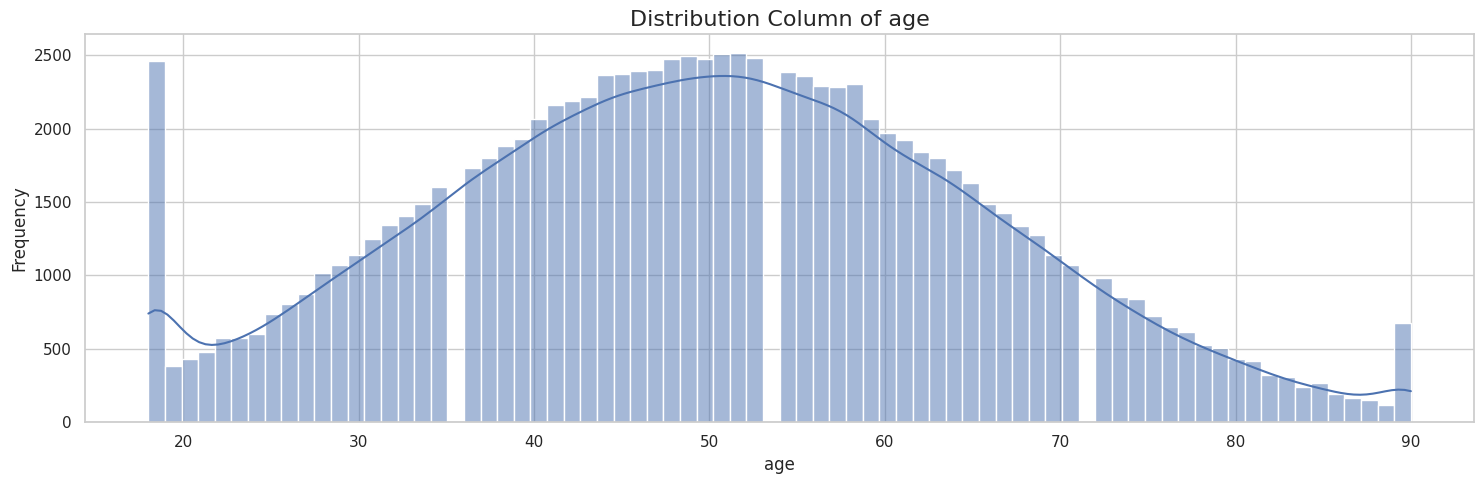

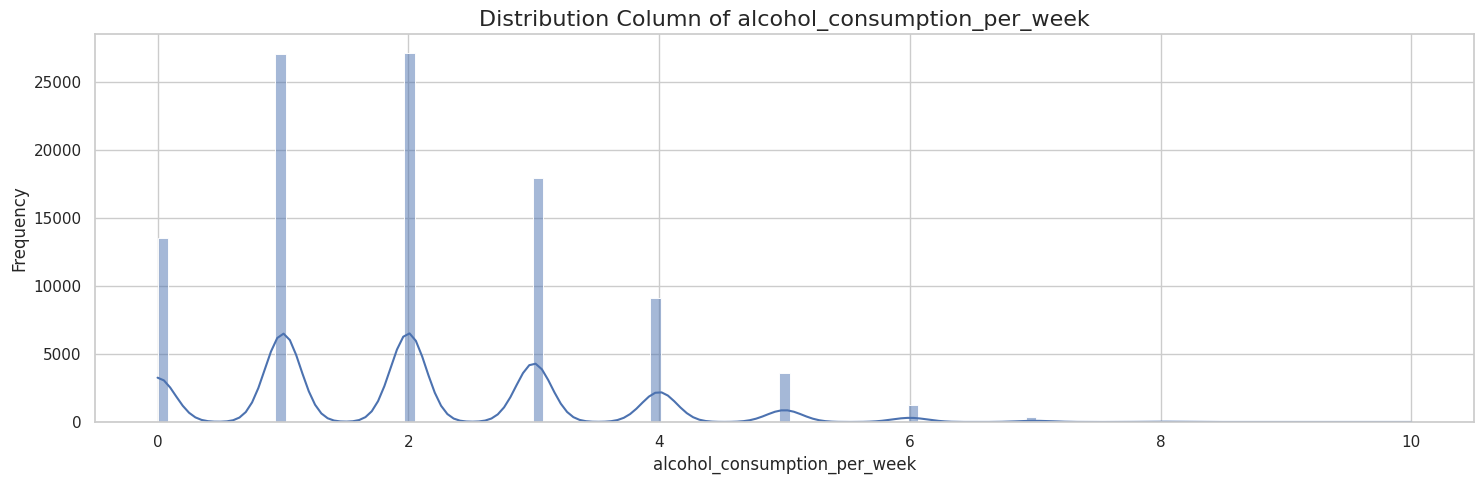

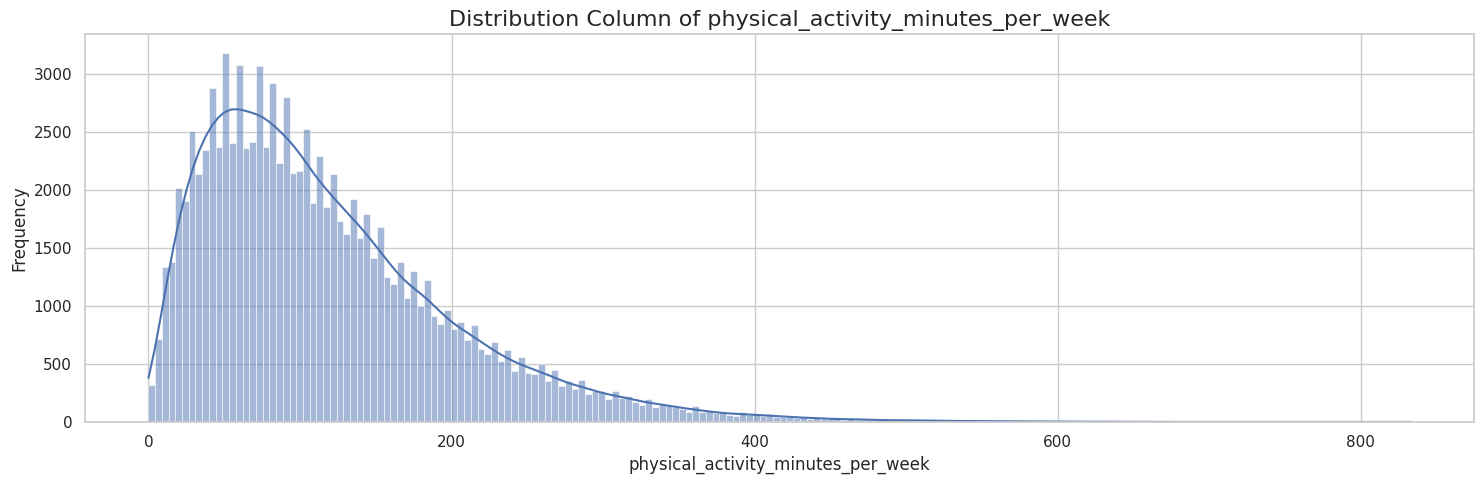

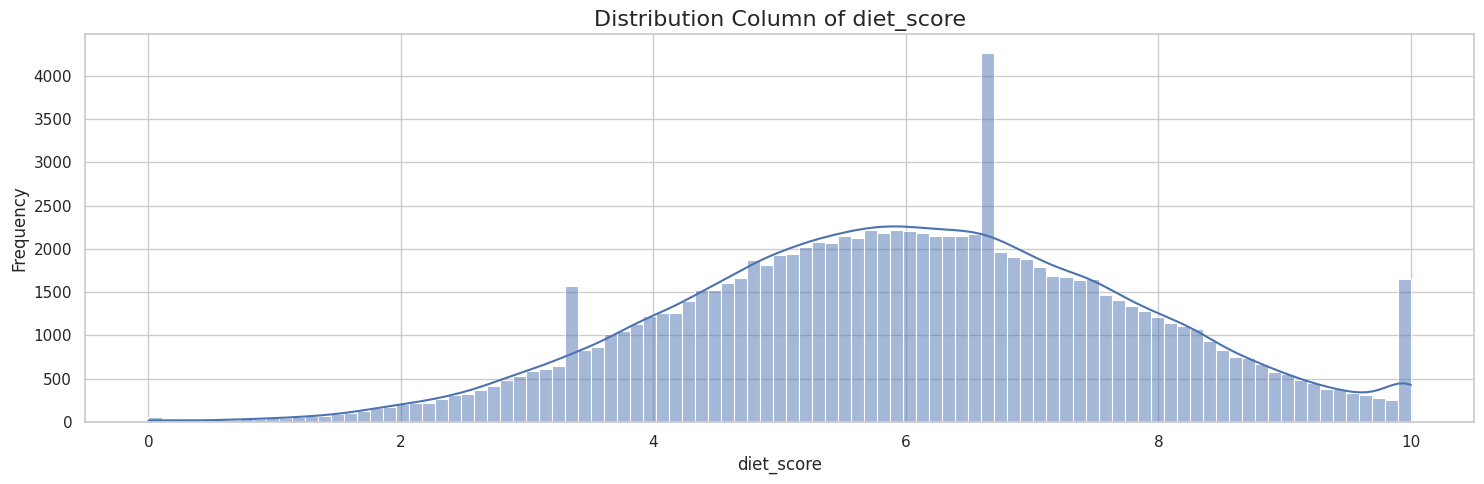

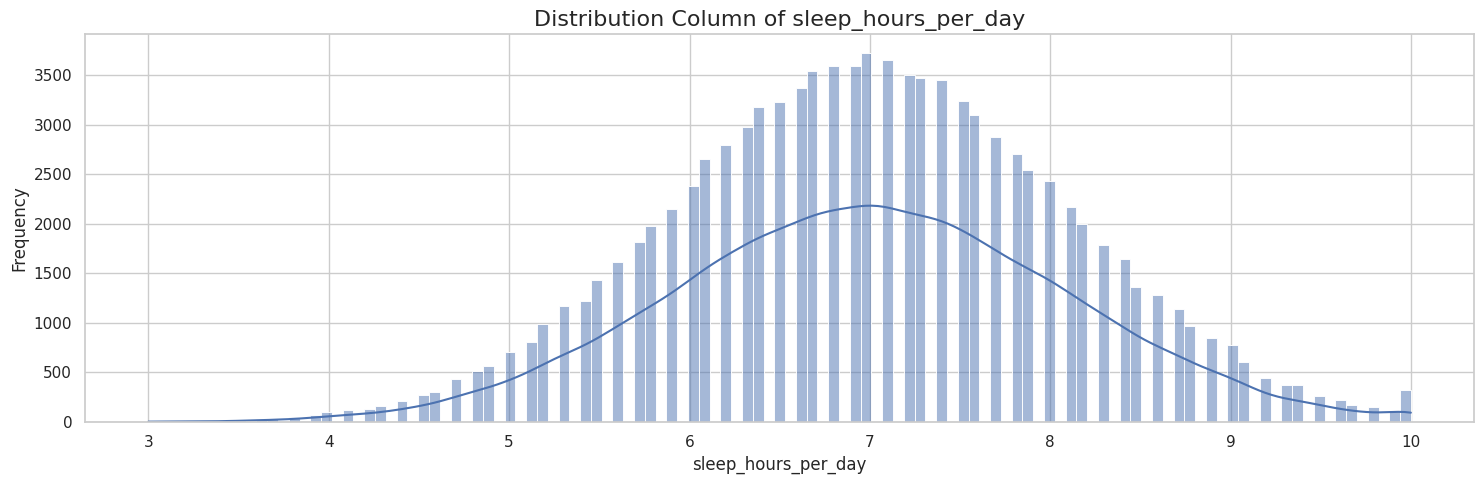

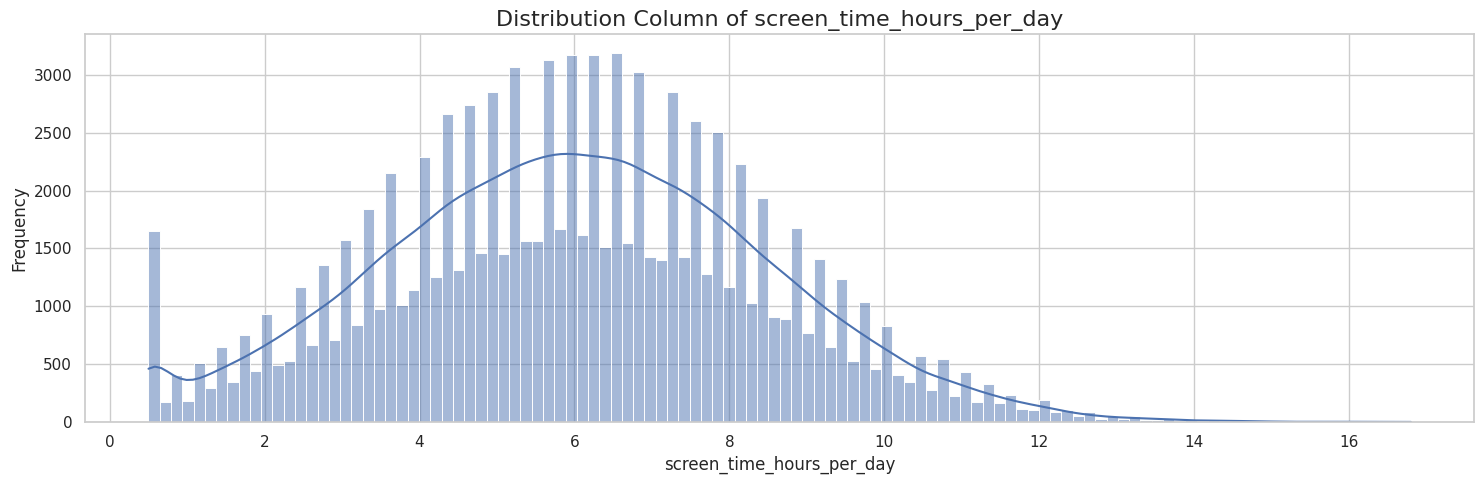

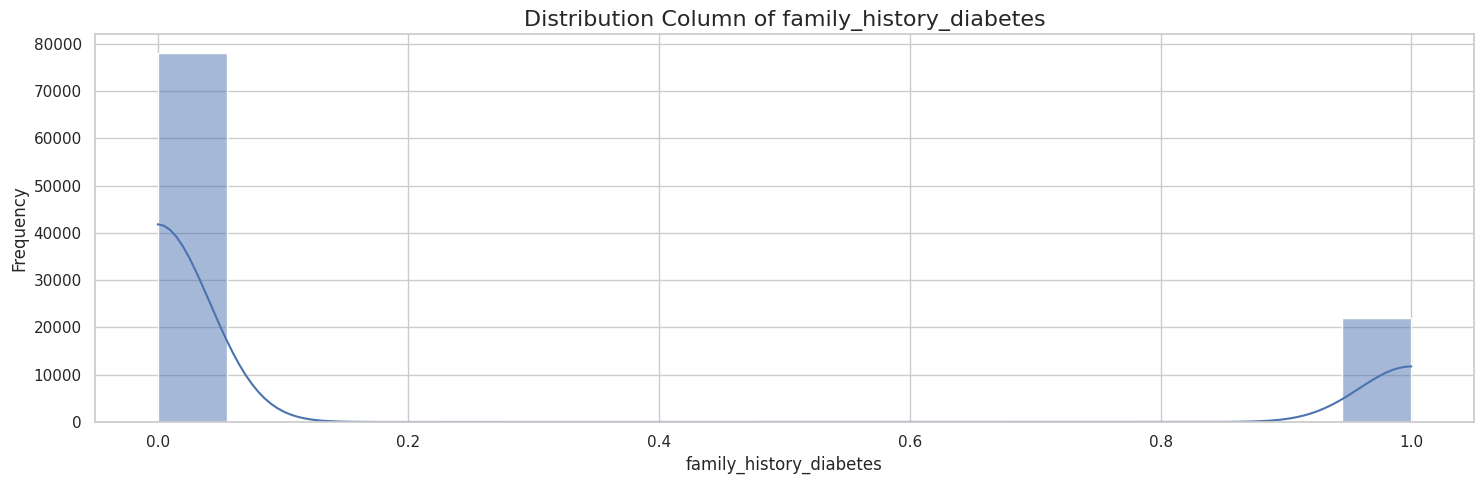

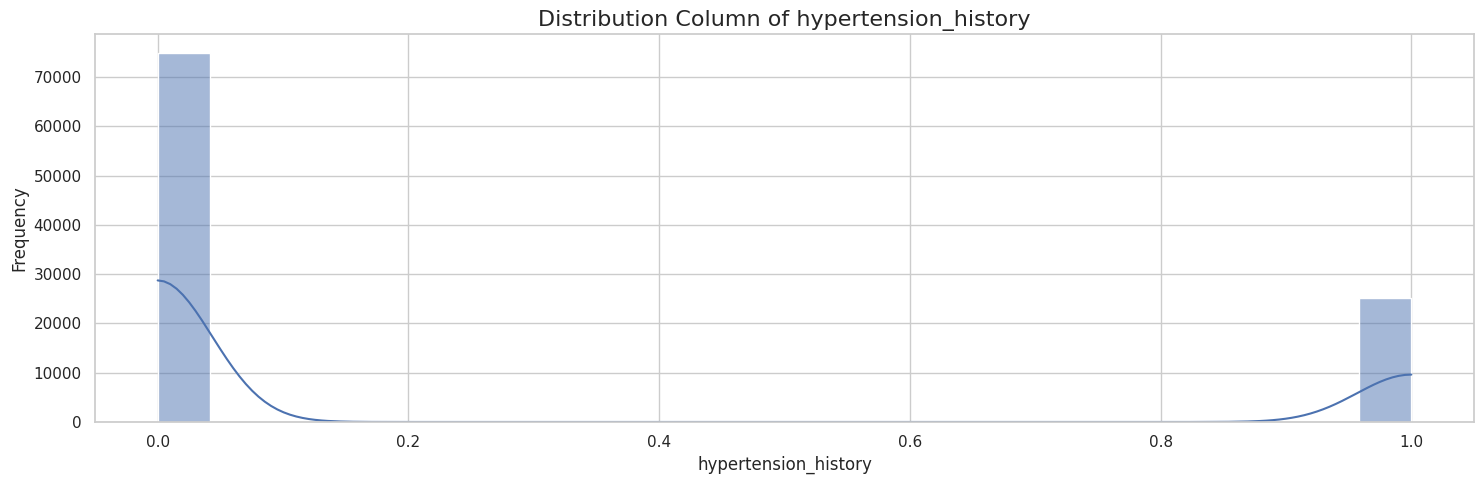

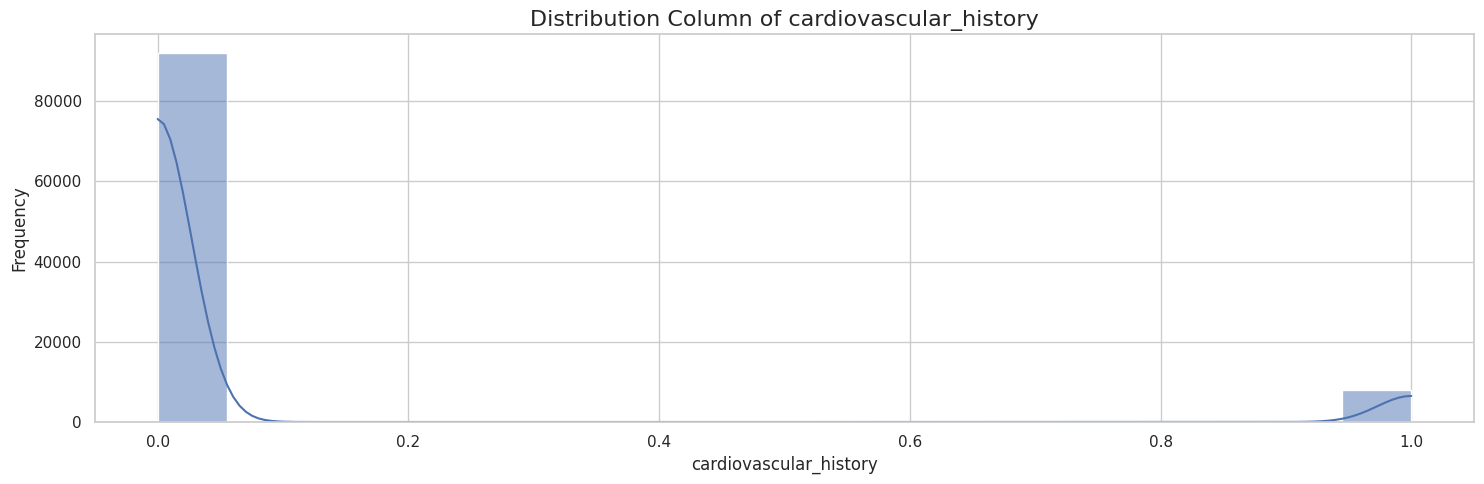

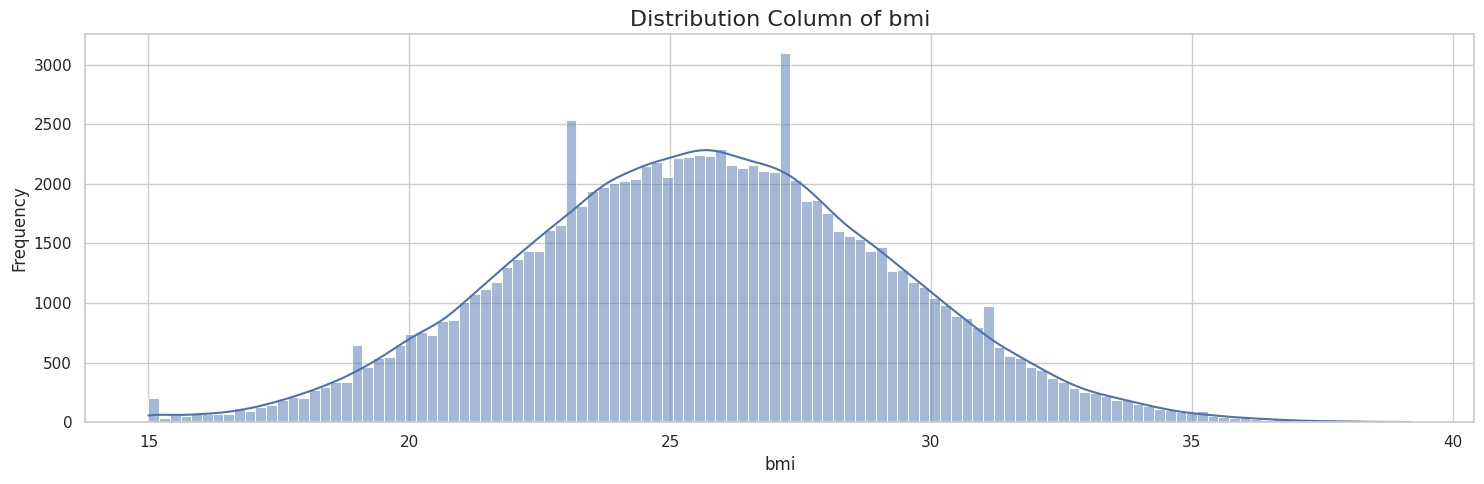

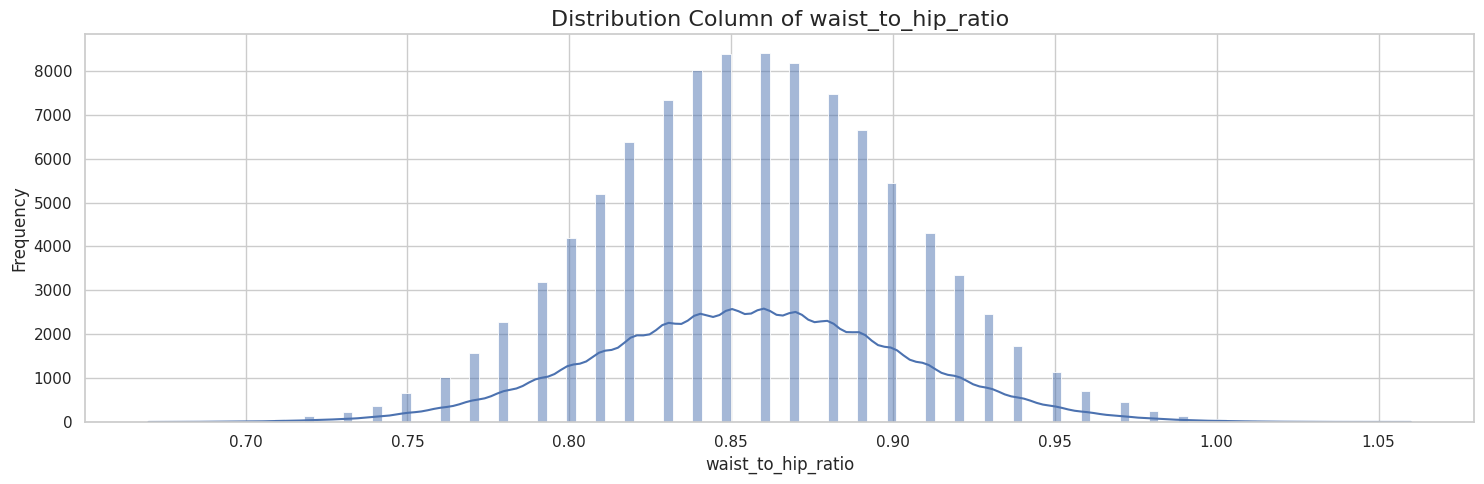

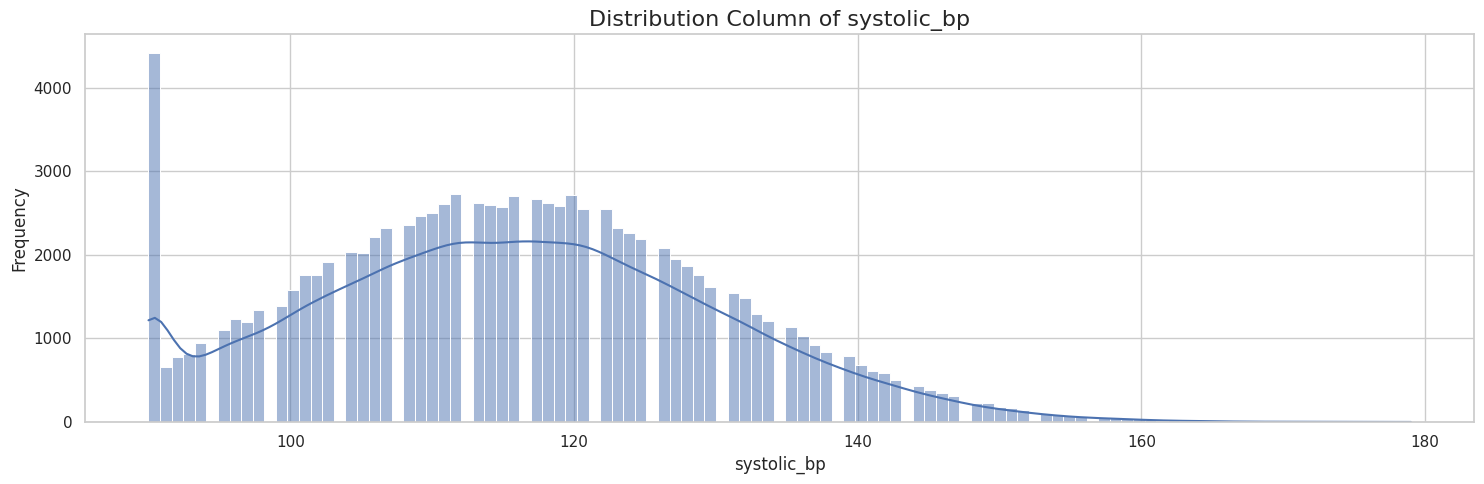

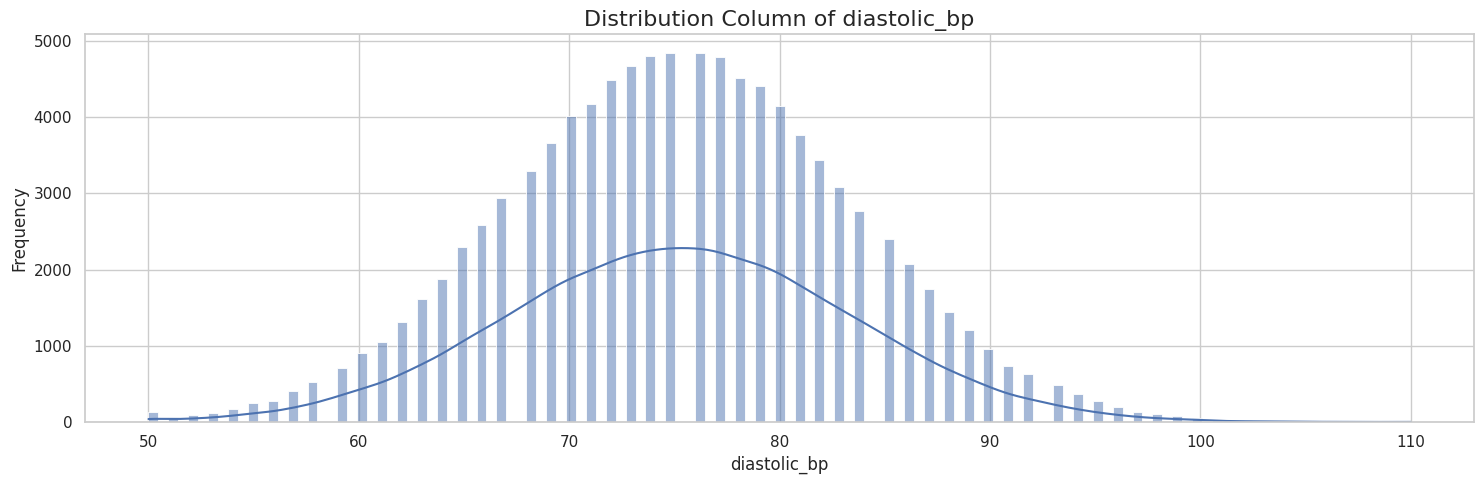

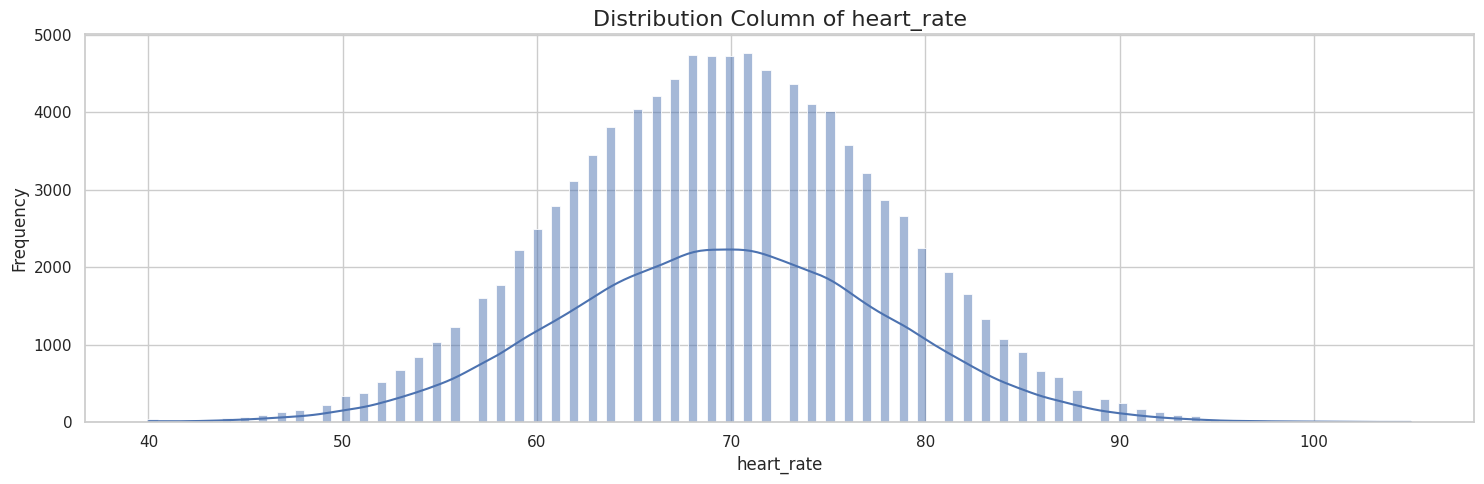

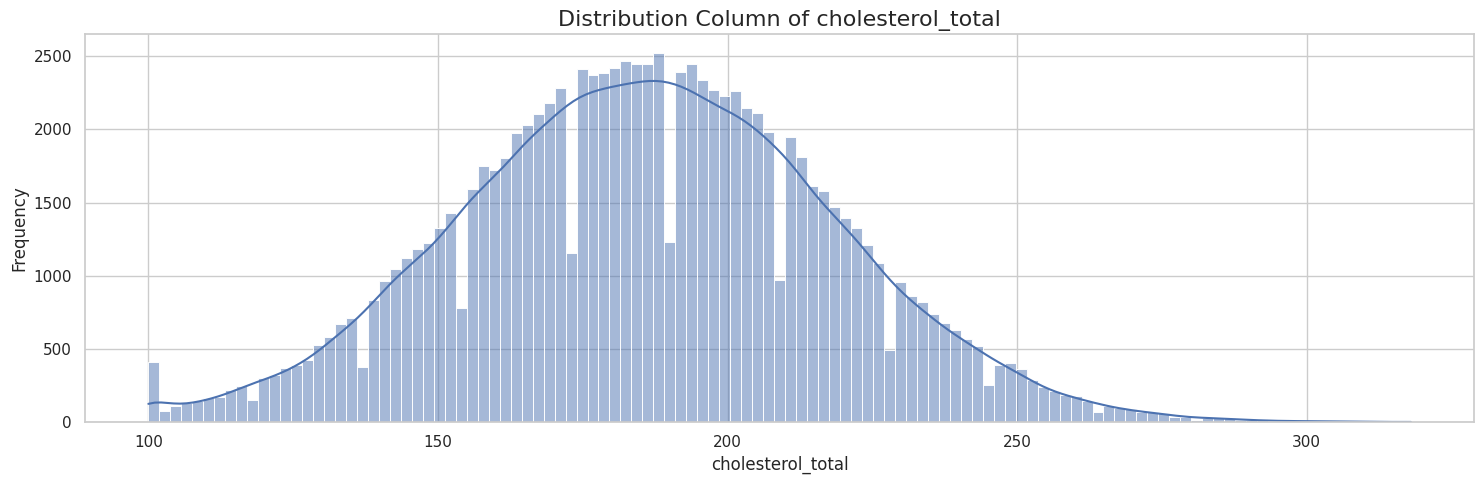

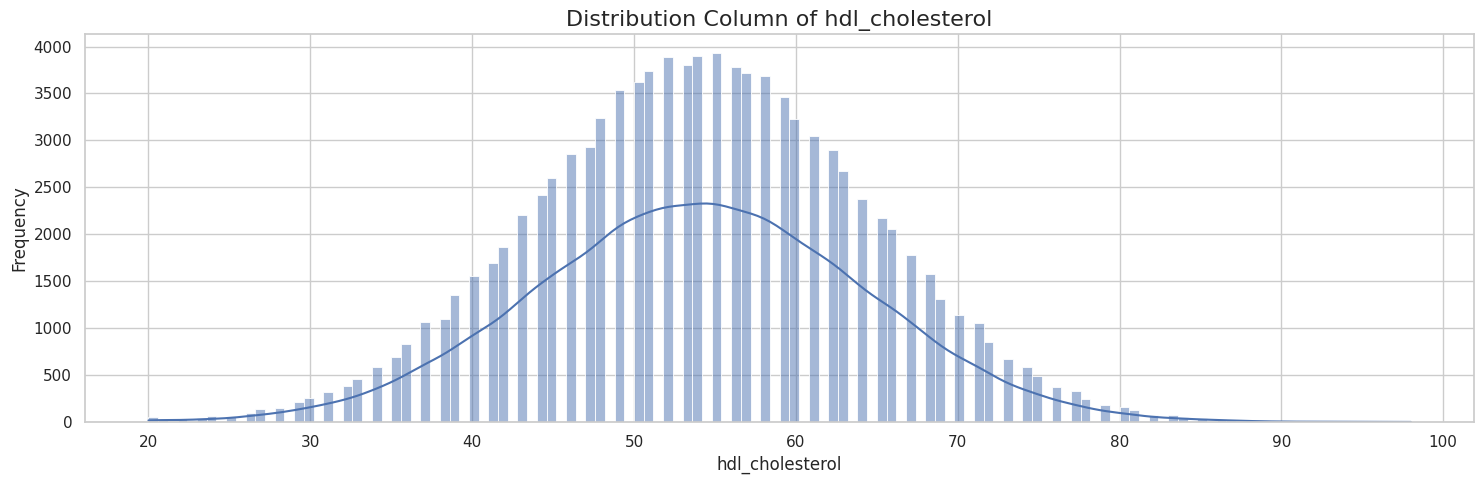

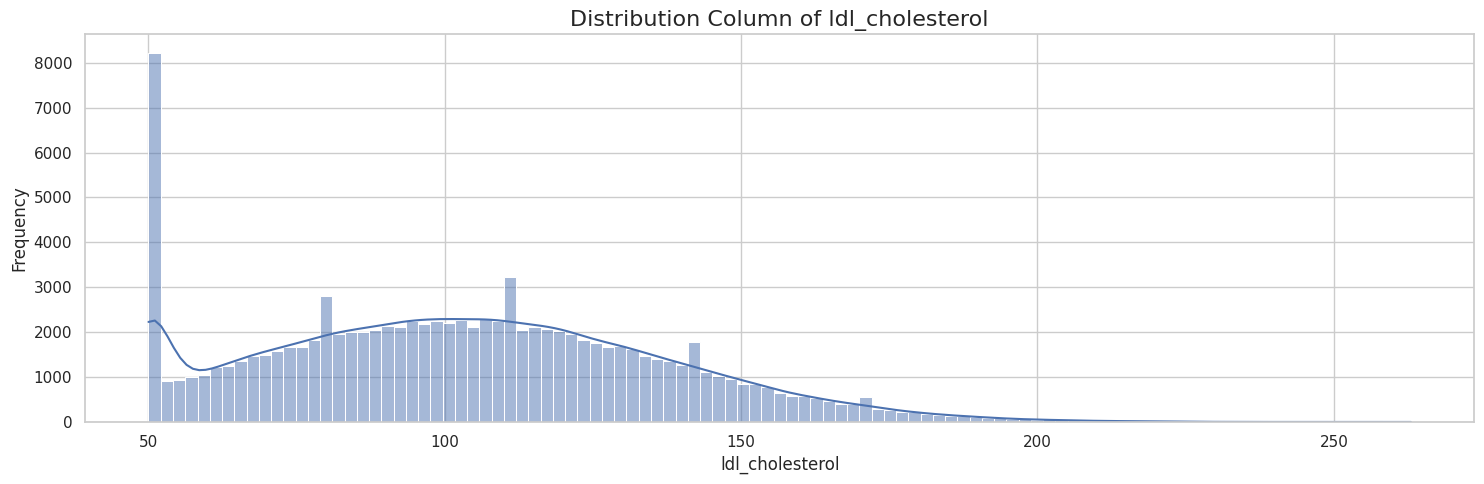

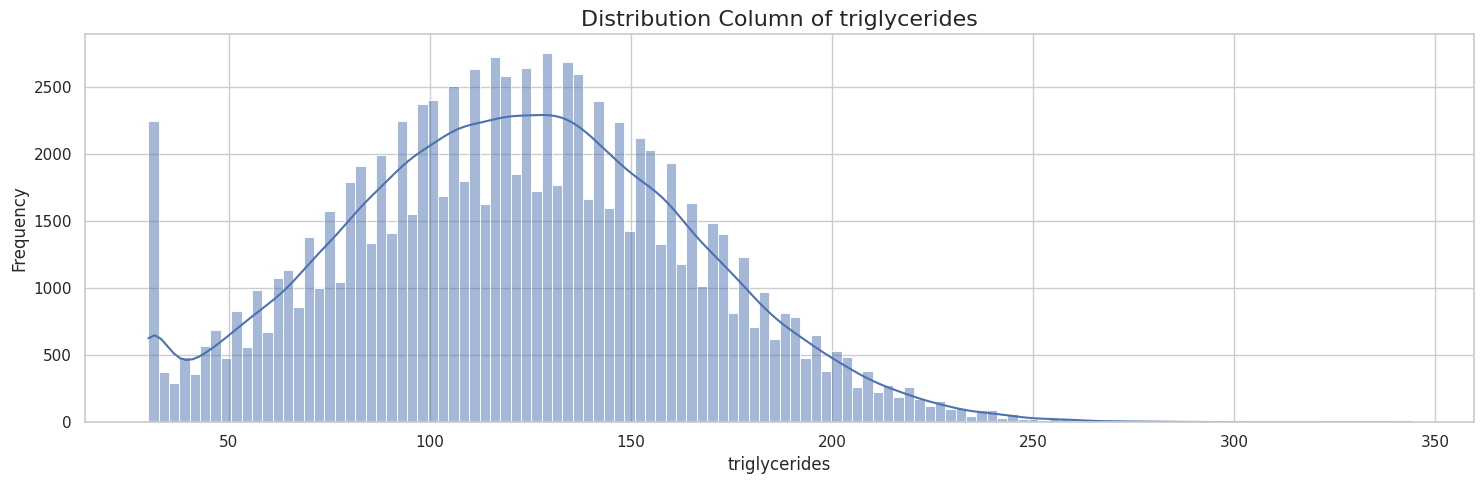

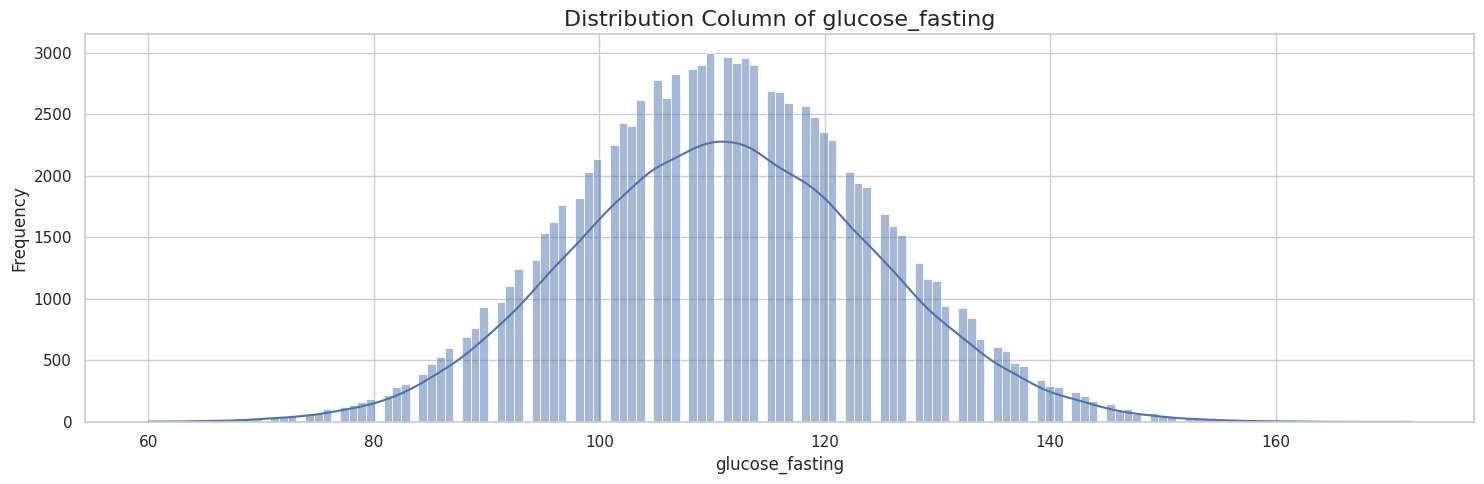

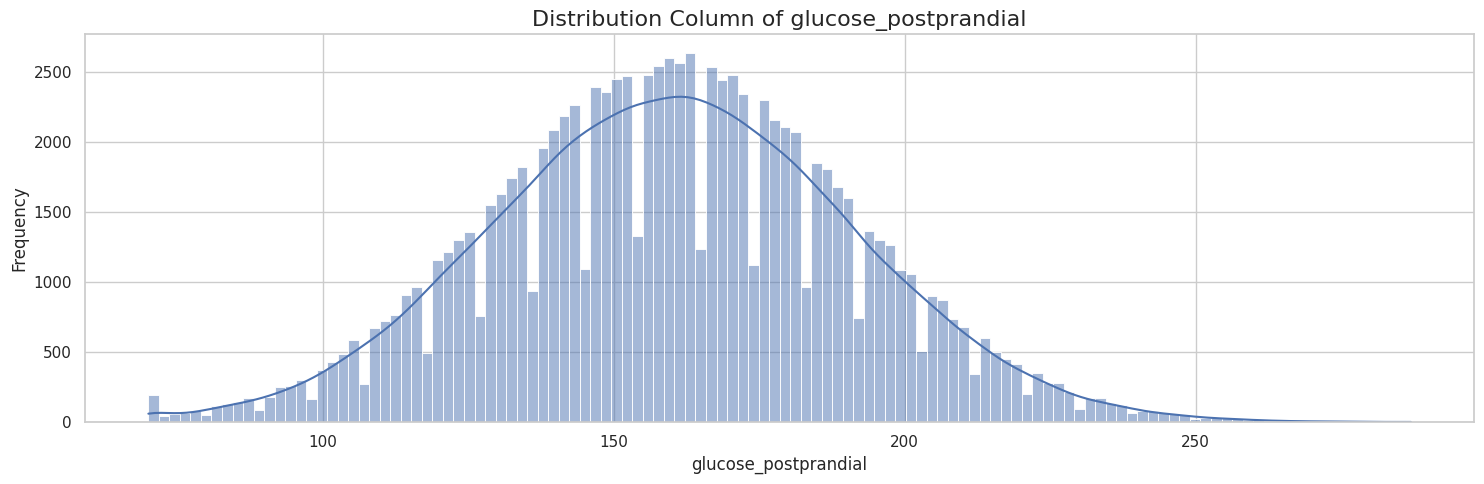

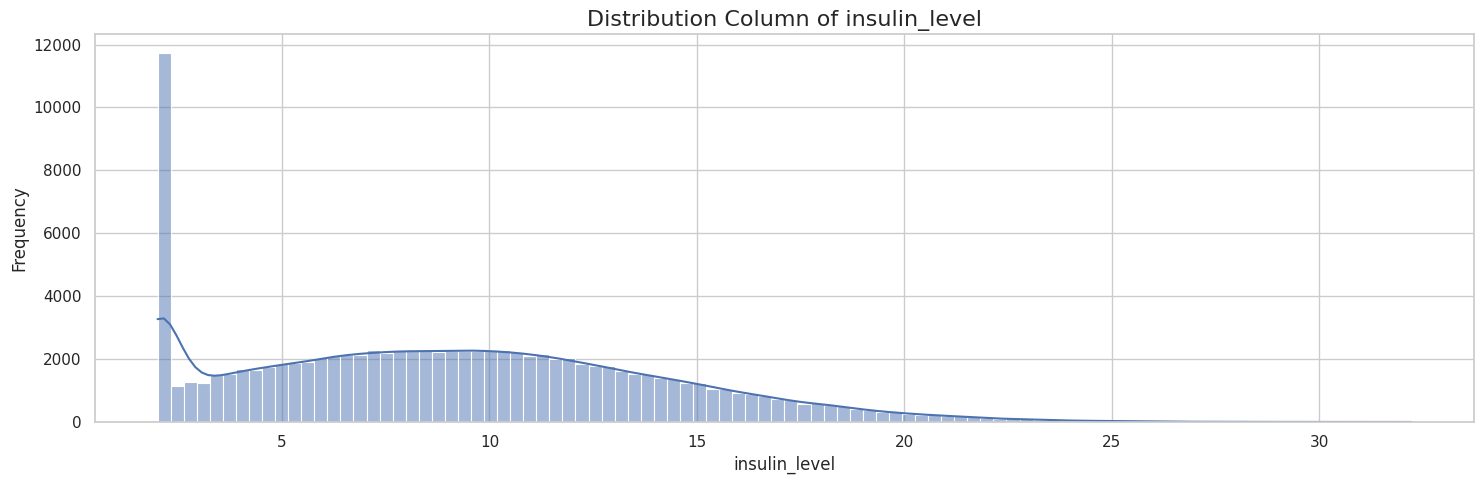

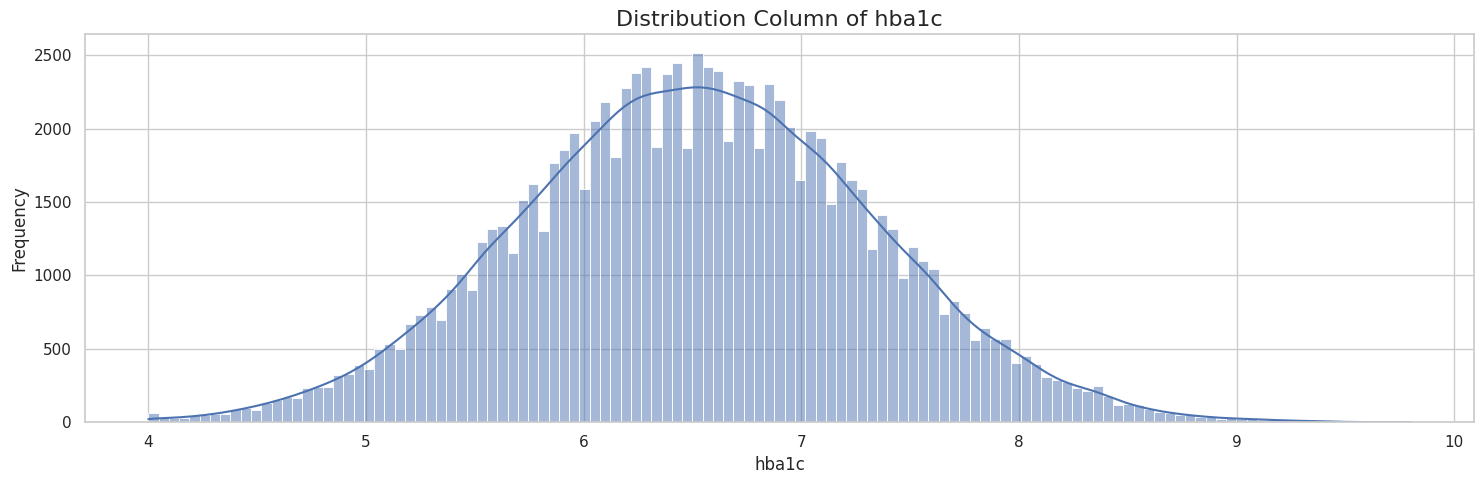

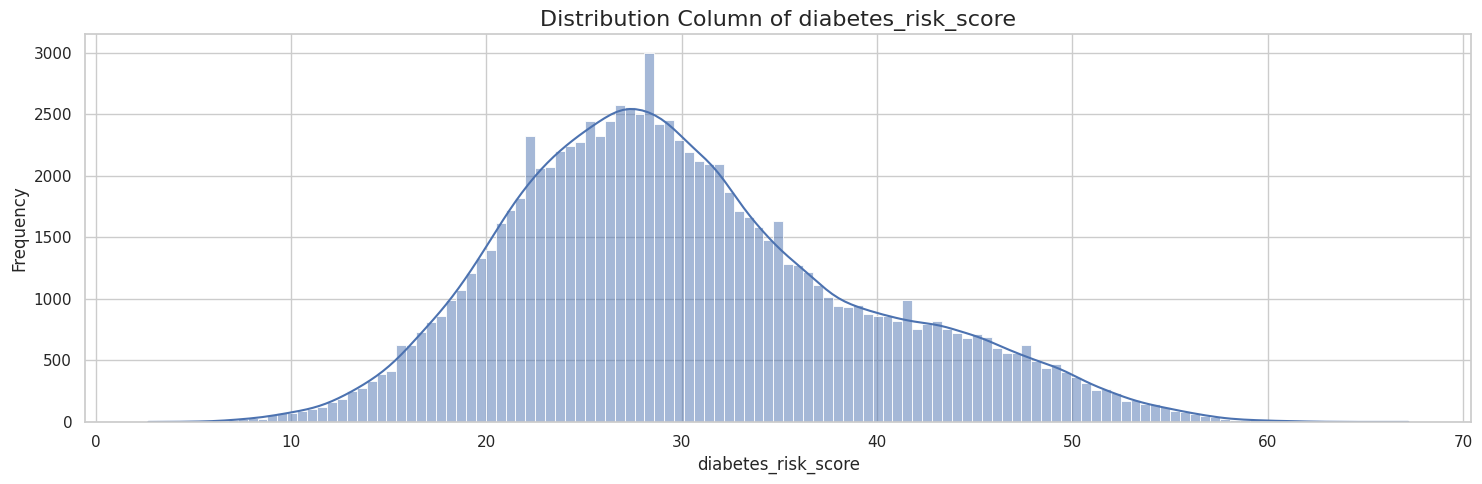

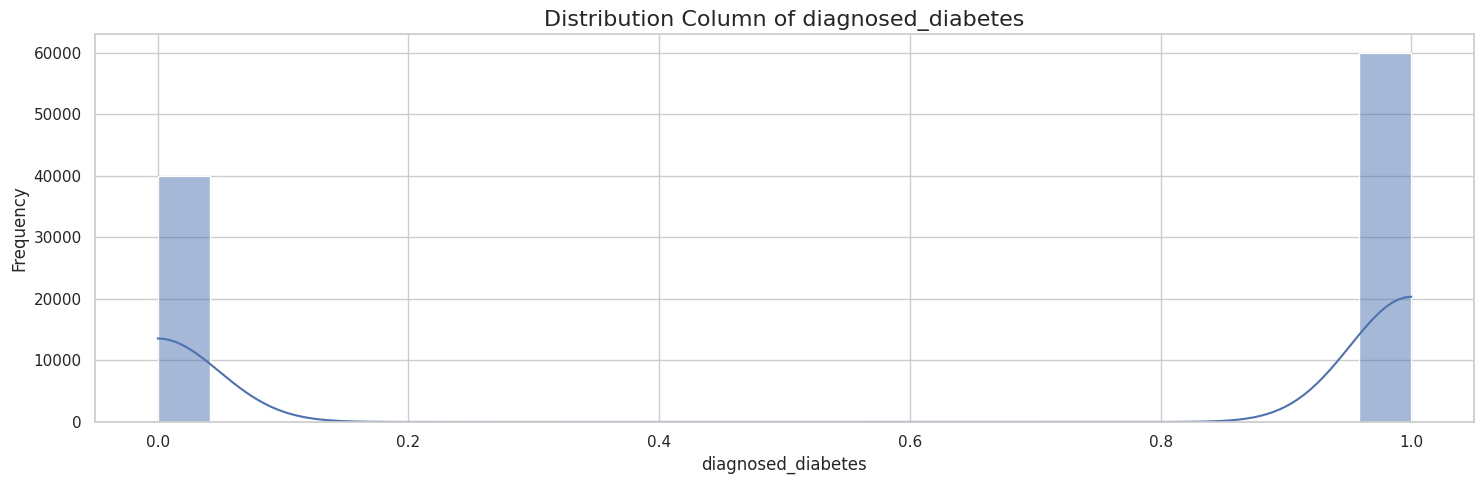

In [10]:
numerical_cols_all = df.select_dtypes(include='number')
sns.set(style="whitegrid")
for column in numerical_cols_all:
  plt.figure(figsize=(15, 5))

  sns.histplot(df[column], kde=True)
  plt.title(f'Distribution Column of {column}', fontsize=16)
  plt.xlabel(column)
  plt.ylabel('Frequency')

  plt.tight_layout()
  plt.show()

## Feature Correlation Analysis

In the final stage of this EDA, a correlation matrix is ​​calculated for all numerical features. This matrix is ​​then visualized as a heatmap, using color to represent the strength and direction of linear relationships between variables.

The primary objective of the correlation analysis is to identify multicollinearity—a condition where two or more independent variables exhibit a very strong relationship with one another. Understanding these correlations is crucial because high multicollinearity can complicate the interpretation of certain models (such as Logistic Regression) and may sometimes indicate the presence of redundant features.

The resulting heatmap reveals several strong positive correlations that are clinically intuitive. For instance, very high correlations are observed between `hba1c` and both `glucose_postprandial` (0.93) and `glucose_fasting` (0.70), given that `HbA1c` is a measure of average blood glucose. Similarly, `waist_to_hip_ratio` and `bmi` (0.77) are strongly correlated, as both serve as indicators of obesity. Despite these strong correlations, no features were removed, as the primary models employed (XGBoost and LightGBM) are inherently robust against the effects of multicollinearity.

### Correlation Visualization with Heatmap

The code below first calculates the Pearson correlation coefficient for each pair of numerical features using the `.corr()` function. The result is a DataFrame (matrix) that is then plotted using `sns.heatmap()`. The parameter `annot=True` is used to display the coefficient values ​​in each cell, `cmap='coolwarm'` sets the color scheme (blue for negative correlation, red for positive), and `fmt='.2f'` formats the numbers to two decimal places. The result is a comprehensive and easy-to-read visualization of the relationships between the features.

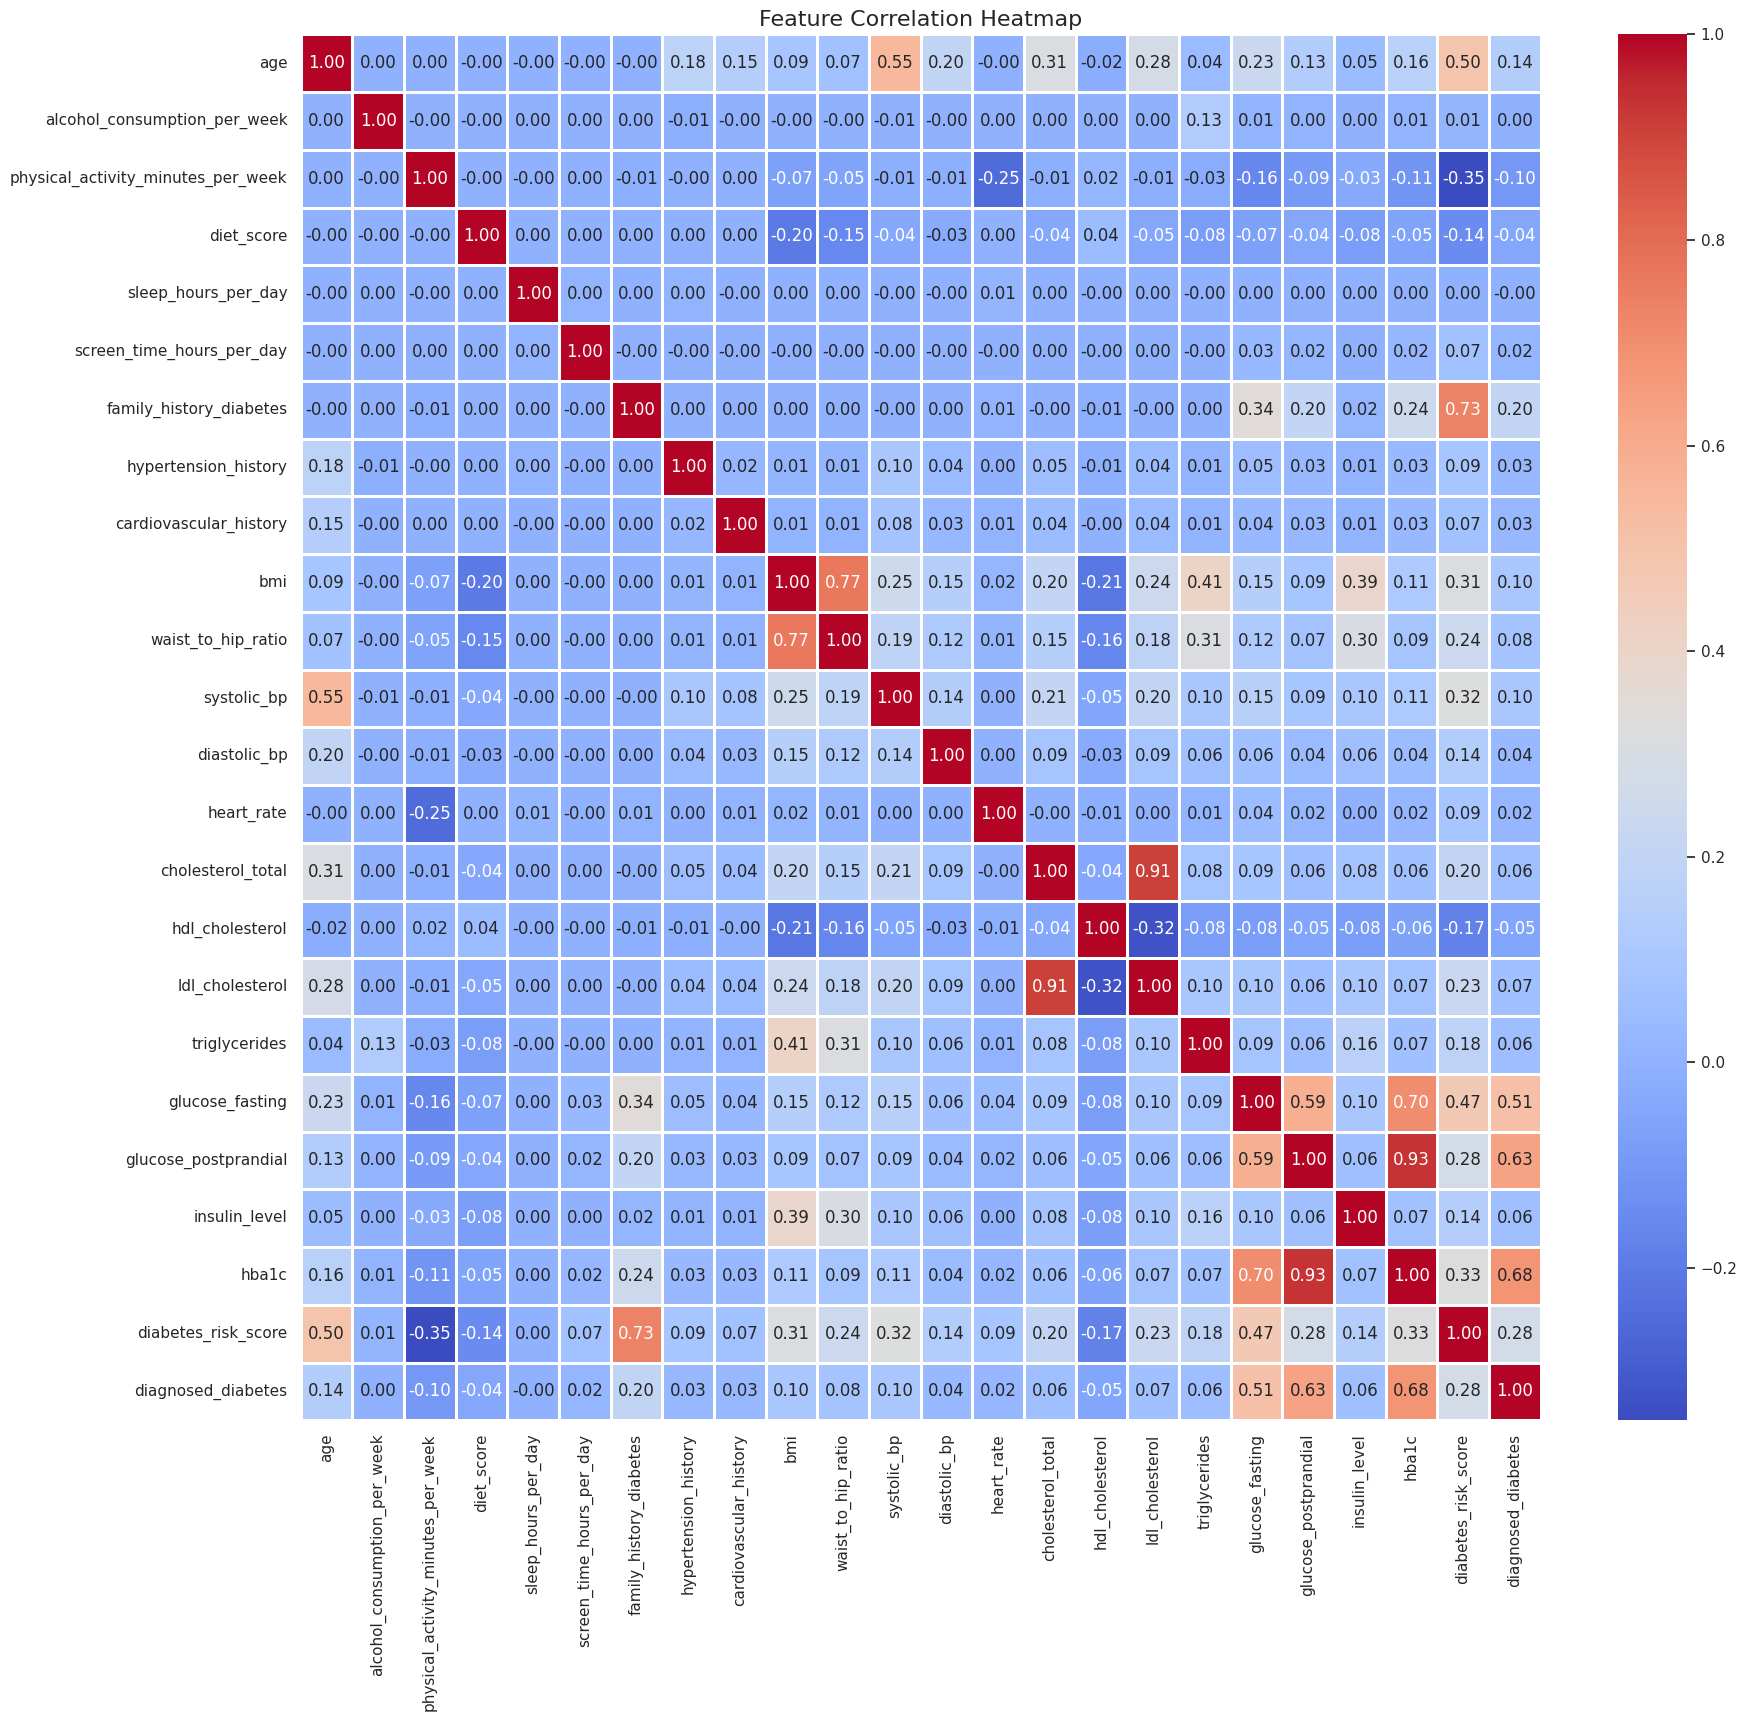

In [11]:
correlation_matrix = numerical_cols_all.corr()
plt.figure(figsize=(20, 18))
sns.heatmap(
  correlation_matrix,
  annot=True,
  cmap='coolwarm',
  fmt='.2f',
  linewidths=1
)
plt.title('Feature Correlation Heatmap', fontsize=16)
plt.show()

# Data Preparation

After understanding the data characteristics, the next stage is data preparation. This process involves transforming and cleaning raw data into a format suitable for training machine learning models.

Raw data is rarely ready for immediate use. This process is crucial for addressing issues such as non-numeric data, varying feature scales, and potential data leakage. Proper data preparation serves as the foundation for building accurate and reliable models.

Through a series of structured steps, a clean, fully numeric, and correctly partitioned dataset is produced—ready for the modeling stage. This process also entails critical decisions, such as handling data leakage, which enhances the validity of the model's final results.

## Categorical Feature Encoding

The first step in data preparation is converting all non-numeric (categorical) data into a numeric format. This process involves reclassifying the target variable and applying appropriate encoding techniques for each type of categorical feature.

Machine learning algorithms fundamentally operate on numbers. Therefore, all text-based features (such as 'Female', 'High School', etc.) must be converted into numeric representations so they can be processed by the model.

Following this process, the entire dataset—including both features and the target—will be in a numeric format, ready for subsequent stages such as scaling and modeling.

### Target Variable Reclassification

The code below first simplifies the five original categories in the `diabetes_stage` column into three more meaningful categories ('No Diabetes', 'Pre-Diabetes', 'Diabetes').

Next, category mapping is performed explicitly using a dictionary (`target_map`) to convert the text categories into sequential numerical values:
- `0`: 'No Diabetes'
- `1`: 'Pre-Diabetes'
- `2`: 'Diabetes'

This explicit mapping approach is important to replace `LabelEncoder` (which sorts categories alphabetically by default: 0 = 'Diabetes', 1 = 'No Diabetes', 2 = 'Pre-Diabetes') and to ensure that the class order `0, 1, 2` remains consistent with the `class_names` list during both evaluation and inference in the backend production stage.

In [12]:
df_encoded = df.copy()

diabetes_stage_map = {
  'No Diabetes': 'No Diabetes',
  'Pre-Diabetes': 'Pre-Diabetes',
  'Type 1': 'Pre-Diabetes',
  'Type 2': 'Diabetes',
  'Gestational': 'Diabetes'
}
df_encoded['diabetes_stage'] = df_encoded['diabetes_stage'].map(diabetes_stage_map)

target_map = {
  'No Diabetes': 0,
  'Pre-Diabetes': 1,
  'Diabetes': 2
}
df_encoded['diabetes_stage'] = df_encoded['diabetes_stage'].map(target_map)

y = df_encoded['diabetes_stage']

### One-Hot Encoding for Nominal Features

This code applies One-Hot Encoding to features that lack an inherent order (nominal features), such as `gender` and `ethnicity`. The `pd.get_dummies()` function automatically creates new binary columns for each category, and `drop_first=True` is used to avoid multicollinearity. As a result, these features are represented numerically without the model making incorrect assumptions about ordering.

In [13]:
cols_onehot = ['gender', 'ethnicity', 'employment_status', 'smoking_status']
df_encoded = pd.get_dummies(df_encoded, columns=cols_onehot, drop_first=True)

### Ordinal Encoding for Ordered Features

For features with an inherent order or hierarchy (ordinal features)—such as `education_level` and `income_level`—Label Encoding will be applied manually using `.map()`. Explicitly defining the order (e.g., 'Low' = 0, 'Lower-Middle' = 1) ensures that this ordinal information is preserved in the numerical representation.

In [14]:
education_map = {
  'No formal': 0,
  'Highschool': 1,
  'Postgraduate': 2,
  'Graduate': 3
}
income_map = {
  'Low': 0,
  'Lower-Middle': 1,
  'Middle': 2,
  'Upper-Middle': 3,
  'High': 4
}

df_encoded['education_level'] = df_encoded['education_level'].map(education_map)
df_encoded['income_level'] = df_encoded['income_level'].map(income_map)

## Data Leakage Prevention

In this subsection, columns that could lead to data leakage are identified and removed. Based on the initial analysis, the columns `diabetes_risk_score` and `diagnosed_diabetes` were dropped from the feature set `X`.

These columns contain information derived—either directly or indirectly—from the target variable (`diabetes_stage`). Including them would allow the model to "cheat" by accessing the answer, resulting in artificially high accuracy that fails to generalize to new data. Removing them ensures the model learns from valid predictors.

Dropping these columns creates a more valid feature dataset (`X`) and ensures that the subsequent model performance evaluation reflects true predictive capability.

In [15]:
X = df_encoded.drop(['diabetes_risk_score', 'diabetes_stage', 'diagnosed_diabetes'], axis=1)

## Dataset Splitting

The cleaned, fully numerical dataset is now split into two separate sets: training data (80%) and testing data (20%).

This split is crucial for objective model evaluation. The model "learns" patterns from the training data, and its performance is subsequently tested on "unseen" testing data. This simulates how the model would perform on new data in a real-world setting.

This results in four datasets—X_train, X_test, y_train, and y_test—ready for use in the modeling and evaluation stages.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Feature Standardization

In this final preparation stage, standardization is applied to numerical features using `StandardScaler`.

Certain models, such as KNN and Logistic Regression, are sensitive to feature scales. Standardization transforms the data to have a mean of 0 and a standard deviation of 1, ensuring that no single feature dominates the learning process simply due to a larger value range. It is important to note that the scaler is "fitted" (`.fit()`) only on `X_train` to prevent information leakage from the test data.

This results in `X_train_scaled` and `X_test_scaled`—scaled versions of the training and test data with uniform feature scaling—ready for training across various model types.

In [17]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model Development

At this stage, four different machine learning models—K-Nearest Neighbors, Logistic Regression, XGBoost, and LightGBM—will be trained separately using the prepared training data (`X_train_scaled` and `y_train`).

The primary objective of this stage is to implement the formulated solution approach: conducting a comparative analysis. By training multiple models, we can objectively compare their performance on the same dataset and identify the most effective algorithm for solving this diabetes stage prediction problem.

Each model will generate a set of predictions on the test data (`y_pred`). These predictions will serve as the basis for the evaluation stage, where metrics such as accuracy, precision, and recall will be measured and compared to determine the best-performing model.

## K-Nearest Neighbors (KNN)

KNN is an instance-based learning model that classifies new data points based on the majority class of their 'k' nearest neighbors.

KNN is implemented as a baseline model in this project. Due to its simplicity, KNN provides a useful reference point for determining whether more complex models (such as XGBoost) actually deliver significant performance improvements.

The KNN model was successfully trained and generated predictions on the test data, which were stored in the `y_pred_knn` variable. These results will be further evaluated to assess the model's capabilities, particularly in identifying minority classes such as 'Pre-Diabetes'.

In [18]:
model_knn = KNeighborsClassifier()
model_knn.fit(X_train_scaled, y_train)
y_pred_knn = model_knn.predict(X_test_scaled)

## Logistic Regression

This model is a linear algorithm that calculates the probability of a data point belonging to a specific class. The parameter `multi_class='multinomial'` is used because there are three target classes, and `max_iter=1000` is set to ensure convergence.

Like KNN, Logistic Regression is implemented as a second baseline model. This model was selected due to its efficiency and high interpretability, and because it often serves as a robust benchmark in medical classification tasks.

The Logistic Regression model was successfully trained, and its predictions were stored in the variable `y_pred_lr`. The model's performance will be directly compared with other models to evaluate the effectiveness of the linear approach on this dataset.

In [19]:
model_lr = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)
model_lr.fit(X_train_scaled, y_train)
y_pred_lr = model_lr.predict(X_test_scaled)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


## XGBoost Classifier

This model operates by sequentially building decision trees, where each new tree focuses on correcting the errors of the preceding one.

XGBoost was implemented as the first advanced model. Numerous studies have shown that XGBoost delivers high predictive performance on tabular datasets, such as medical data. The objective was to assess the extent of performance improvement achieved relative to the baseline model.

The XGBoost model was successfully trained, and its predictions were stored in `y_pred_xgb`. The model is expected to demonstrate significant improvements in evaluation metrics, particularly regarding recall for classes that are difficult to predict.

In [20]:
model_xgb = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
model_xgb.fit(X_train_scaled, y_train)
y_pred_xgb = model_xgb.predict(X_test_scaled)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [06:40:48] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


## LightGBM Classifier

The LightGBM (Light Gradient Boosting Machine) model is another implementation of gradient boosting. LightGBM is known for its speed and efficiency without compromising accuracy.

LightGBM was implemented as a second advanced model to be compared with XGBoost. Its advantage in training speed makes it an attractive choice. The objective was to determine whether LightGBM could deliver performance comparable to, or even better than, XGBoost on this dataset.

The LightGBM model was successfully trained, and its predictions were stored in `y_pred_lgb`. This model is a strong candidate for the project's final model, and its performance will be thoroughly evaluated in the next stage.

In [21]:
model_lgb = LGBMClassifier()
model_lgb.fit(X_train_scaled, y_train)
y_pred_lgb = model_lgb.predict(X_test_scaled)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.017135 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2730
[LightGBM] [Info] Number of data points in the train set: 80000, number of used features: 35
[LightGBM] [Info] Start training from score -2.522609
[LightGBM] [Info] Start training from score -1.144761
[LightGBM] [Info] Start training from score -0.508412


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


# Model Evaluation

At this stage, a quantitative evaluation of all trained models is conducted. The process begins with an initial performance assessment of the four models to select the best one, proceeds to the optimization of the chosen model, and concludes with a final evaluation using test data.

Evaluation is a crucial phase for measuring how effectively a model addresses the problem at hand. Without objective evaluation using appropriate metrics, the developed solution cannot be validated. The primary objective is to obtain quantitative evidence regarding model performance before drawing conclusions.

This stage will yield a clear performance comparison among the models, a final optimized model, and a final performance report that serves as the benchmark for the project's success.

## Initial Model Performance Comparison

We take the prediction results from the four models (`y_pred_knn`, `y_pred_lr`, `y_pred_xgb`, `y_pred_lgb`) and evaluate them using a Classification Report and a Confusion Matrix.

This step forms the core of the comparative analysis. By displaying performance metrics (Precision, Recall, F1-Score) and error visualizations (Confusion Matrix) side-by-side, we can directly compare the strengths and weaknesses of each model. This enables data-driven decision-making regarding which model performs best, particularly in detecting critical classes such as 'Pre-Diabetes' and 'Diabetes'.

Initial evaluation results indicate that the ensemble models (XGBoost and LightGBM) significantly outperform the baseline models. LightGBM stands out in particular for achieving perfect recall (1.00) for the 'Pre-Diabetes' and 'Diabetes' classes, making it the strongest candidate for further optimization.

In [22]:
all_predictions = {
  "K-Nearest Neighbors": y_pred_knn,
  "Logistic Regression": y_pred_lr,
  "XGBoost Classifier": y_pred_xgb,
  "LightGBM Classifier": y_pred_lgb
}

class_names = ['No Diabetes', 'Pre-Diabetes', 'Diabetes']
class_indices = [str(i) for i in range(len(class_names))]

for model_name, y_pred in all_predictions.items():
  print(f"===================== {model_name} =====================")

  print("\nClassification Report:")
  print(classification_report(y_test, y_pred, target_names=class_names))

  print("\n")

===================== K-Nearest Neighbors =====================

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.58      0.46      0.52      1561
Pre-Diabetes       0.60      0.64      0.62      6503
    Diabetes       0.82      0.82      0.82     11936

    accuracy                           0.73     20000
   macro avg       0.67      0.64      0.65     20000
weighted avg       0.73      0.73      0.73     20000



===================== Logistic Regression =====================

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.80      0.68      0.73      1561
Pre-Diabetes       0.75      0.73      0.74      6503
    Diabetes       0.86      0.89      0.88     11936

    accuracy                           0.82     20000
   macro avg       0.80      0.77      0.78     20000
weighted avg       0.82      0.82      0.82     20000



===================== XGBoost Classifier =================

In [23]:
accuracy_scores = []
for model_name, y_pred in all_predictions.items():
  accuracy = accuracy_score(y_test, y_pred)
  accuracy_scores.append({'Model': model_name, 'Accuracy': accuracy})

accuracy_df = pd.DataFrame(accuracy_scores)
accuracy_df = accuracy_df.sort_values(by='Accuracy', ascending=False).reset_index(drop=True)
accuracy_df.index += 1
accuracy_df = accuracy_df.set_index('Model')

display(accuracy_df.style.format({'Accuracy': '{:.2%}'}))

,Accuracy
Model,
LightGBM Classifier,91.83%
XGBoost Classifier,91.62%
Logistic Regression,82.17%
K-Nearest Neighbors,73.33%


## Hyperparameter Tuning for LightGBM

After selecting LightGBM as the best model, an optimization process known as hyperparameter tuning was performed. `GridSearchCV` was used to systematically test various hyperparameter combinations (such as `learning_rate`, `max_depth`, etc.) and identify the best one.

Models trained with default parameters rarely achieve peak performance. Tuning aims to discover the optimal configuration that best suits the dataset's characteristics. Using `GridSearchCV` with cross-validation ensures the search is robust and avoids overfitting to a single data split, resulting in a more reliable model.

This process successfully identified the best hyperparameter combination, yielding a cross-validation F1 score of 0.9205. The optimized model (`best_lgbm_model`) was then saved for final evaluation.

In [24]:
lgbm = lgb.LGBMClassifier(random_state=42)

param_grid = {
  'n_estimators': [100, 200, 500],
  'learning_rate': [0.01, 0.05, 0.1],
  'max_depth': [3, 5, 7],
  'num_leaves': [15, 31, 63],
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
  estimator=lgbm,
  param_grid=param_grid,
  scoring='f1_weighted',
  cv=cv_strategy,
  n_jobs=-1,
  verbose=2
)

grid_search.fit(X_train_scaled, y_train)

print("\nBest Hyperparameters Found:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 (Weighted) Score:")
print(f"{grid_search.best_score_:.4f}")

best_lgbm_model = grid_search.best_estimator_

Fitting 5 folds for each of 81 candidates, totalling 405 fits
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.016418 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2730
[LightGBM] [Info] Number of data points in the train set: 80000, number of used features: 35
[LightGBM] [Info] Start training from score -2.522609
[LightGBM] [Info] Start training from score -1.144761
[LightGBM] [Info] Start training from score -0.508412
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf

Best Hyperparameters Found:
{'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 200, 'num_leaves': 15}

Best Cross-Validation F1 (Weighted) Score:
0.9205


## Feature Importance Analysis

After obtaining the best LightGBM model, information regarding feature importance was extracted. This represents the score assigned by the model to each feature, indicating the extent of that feature's contribution to prediction decisions. These scores were then visualized using a bar plot to display the ranking of features from most to least important.

While having an accurate model is important, understanding *why* it is accurate is often more valuable. This analysis opens the model's "black box," allowing for the interpretation of its behavior. Identifying the most influential features yields deep clinical and lifestyle insights, directly addressing one of the project's primary objectives.

The feature importance visualization yielded clear and significant findings. `glucose_fasting` (fasting blood sugar) proved to be the most dominant predictor, followed by `age`, `hba1c`, and `physical_activity_minutes_per_week`. These findings align closely with medical knowledge, confirming that glycemic indicators and lifestyle factors are key determinants in predicting the stages of diabetes.

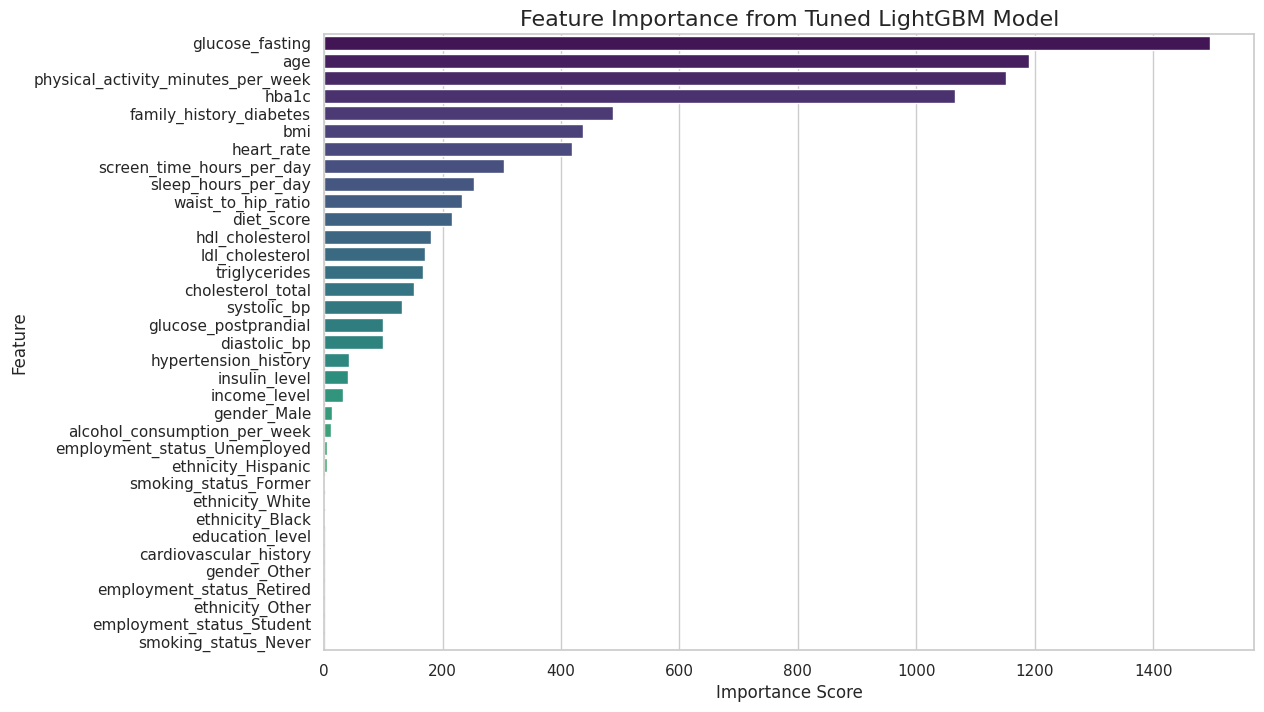

In [25]:
feature_importances = best_lgbm_model.feature_importances_

feature_df = pd.DataFrame({
  'Feature': X.columns,
  'Importance': feature_importances
})

feature_df = feature_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_df, hue='Feature', palette='viridis', legend=False)
plt.title('Feature Importance from Tuned LightGBM Model', fontsize=16)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.show()

## Final LightGBM Evaluation on Test Set

In this final stage, the best-tuned LightGBM model (`best_lgbm_model`) is used to generate predictions on the test data (`X_test_scaled`) that had been kept separate until now.

This serves as the true test for the model. Evaluation on the test set provides the most honest estimate of how well the model will perform on new, real-world data. It validates whether the performance improvements observed during cross-validation truly generalize.

The final evaluation results are highly satisfactory, yielding a weighted average F1-score of 0.92. Most importantly, the model maintains perfect recall (1.00) for both 'Pre-Diabetes' and 'Diabetes'. This confirms that the optimized model is not only accurate but also highly reliable from a clinical perspective.

In [26]:
final_predictions = best_lgbm_model.predict(X_test_scaled)

print("Final Classification Report on Unseen Test Data:")
print(classification_report(y_test, final_predictions, target_names=class_names))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Final Classification Report on Unseen Test Data:
              precision    recall  f1-score   support

 No Diabetes       0.86      1.00      0.92      1561
Pre-Diabetes       0.83      1.00      0.90      6503
    Diabetes       1.00      0.86      0.93     11936

    accuracy                           0.92     20000
   macro avg       0.89      0.95      0.92     20000
weighted avg       0.93      0.92      0.92     20000



# Production Model & Artifact Export

This stage bridges research and production deployment. All artifacts necessary for serving the model via the FastAPI backend and Streamlit dashboard are serialized and saved to the `artifacts/` directory:

1. `lgbm_model.joblib`: The tuned LightGBM classifier.
2. `scaler.joblib`: The fitted `StandardScaler` object.
3. `feature_columns.json`: The exact ordering of all 35 features post-encoding for input validation and alignment.
4. `metadata.json`: Model hyperparameters, CV metrics, test evaluation scores, target class mapping, and feature importances.
5. `presets.json`: Realistic patient profile samples extracted from the dataset (Healthy, Pre-Diabetes, Diabetes) for 1-click simulation in the frontend.

In [27]:
artifacts_dir = 'artifacts'
os.makedirs(artifacts_dir, exist_ok=True)

model_filepath = os.path.join(artifacts_dir, 'lgbm_model.joblib')
joblib.dump(best_lgbm_model, model_filepath)
print(f"Model successfully saved to: {model_filepath}")

scaler_filepath = os.path.join(artifacts_dir, 'scaler.joblib')
joblib.dump(scaler, scaler_filepath)
print(f"Scaler successfully saved to: {scaler_filepath}")

feature_columns = list(X.columns)
feature_columns_filepath = os.path.join(artifacts_dir, 'feature_columns.json')
with open(feature_columns_filepath, 'w', encoding='utf-8') as f:
    json.dump(feature_columns, f, indent=2)
print(f"[OK] Feature list ({len(feature_columns)} features) saved to: {feature_columns_filepath}")

Model successfully saved to: artifacts/lgbm_model.joblib
Scaler successfully saved to: artifacts/scaler.joblib
[OK] Feature list (35 features) saved to: artifacts/feature_columns.json


In [28]:
feature_importance_list = []
for feat, imp in zip(X.columns, best_lgbm_model.feature_importances_):
    feature_importance_list.append({"feature": feat, "importance": float(imp)})
feature_importance_list.sort(key=lambda x: x["importance"], reverse=True)

eval_report = classification_report(y_test, final_predictions, target_names=class_names, output_dict=True)

metadata = {
    "project_name": "Diabetes Predictive Analytics",
    "model_type": "LightGBM Classifier",
    "best_hyperparameters": grid_search.best_params_,
    "cv_f1_weighted": float(grid_search.best_score_),
    "test_evaluation": {
        "accuracy": float(eval_report["accuracy"]),
        "weighted_f1": float(eval_report["weighted avg"]["f1-score"]),
        "macro_f1": float(eval_report["macro avg"]["f1-score"]),
        "classification_report": eval_report
    },
    "target_classes": {
        0: "No Diabetes",
        1: "Pre-Diabetes",
        2: "Diabetes"
    },
    "mappings": {
        "education_level": education_map,
        "income_level": income_map,
        "nominal_columns": cols_onehot,
        "target_map": target_map
    },
    "feature_importance": feature_importance_list,
    "num_features": len(feature_columns)
}

metadata_filepath = os.path.join(artifacts_dir, 'metadata.json')
with open(metadata_filepath, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2)
print(f"Comprehensive metadata saved to: {metadata_filepath}")

Comprehensive metadata saved to: artifacts/metadata.json


In [29]:
input_cols = [col for col in df.columns if col not in ['diabetes_risk_score', 'diagnosed_diabetes', 'diabetes_stage']]

sample_no_diabetes = df[df['diabetes_stage'] == 'No Diabetes'][input_cols].iloc[0].to_dict()
sample_pre_diabetes = df[df['diabetes_stage'] == 'Pre-Diabetes'][input_cols].iloc[0].to_dict()
sample_diabetes = df[df['diabetes_stage'] == 'Type 2'][input_cols].iloc[0].to_dict()

def clean_preset_values(data_dict):
    clean_dict = {}
    for k, v in data_dict.items():
        if isinstance(v, (np.integer, int)):
            clean_dict[k] = int(v)
        elif isinstance(v, (np.floating, float)):
            clean_dict[k] = round(float(v), 2)
        else:
            clean_dict[k] = str(v)
    return clean_dict

presets = {
    "Healthy Profile (Low Risk)": clean_preset_values(sample_no_diabetes),
    "Pre-Diabetic Profile (Moderate Risk)": clean_preset_values(sample_pre_diabetes),
    "Diabetic Profile (High Risk)": clean_preset_values(sample_diabetes)
}

presets_filepath = os.path.join(artifacts_dir, 'presets.json')
with open(presets_filepath, 'w', encoding='utf-8') as f:
    json.dump(presets, f, indent=2)
print(f"Patient presets saved to: {presets_filepath}")

Patient presets saved to: artifacts/presets.json
